## ⚠️ Review notes — weaknesses found in the original notebook, and the fixes applied below

| # | Severity | Weakness in the original notebook | Fix applied (see the matching section below) |
|---|----------|------------------------------------|--------------|
| 1 | **Critical** | `evaluate()` fed the **real test mask** into `spatial_encoder()` — the model was conditioned on the answer it was being scored against (label leakage). | §16: test-time spatial conditioning uses a **zero mask**. |
| 2 | **Critical** | `Diffusion(T=1, device=device)` in §12 — paper specifies `T=1000`; with `T=1`, `alpha_hat[0] ≈ 0.9999`, almost no noise was ever injected. | §13: `T=1000` restored. |
| 3 | **Critical** | `evaluate()` called `torch.sigmoid()` on the model output, which had *already* passed through `nn.Sigmoid` inside the model — a double sigmoid. | §16: single sigmoid, applied once, inside the model only. |
| 4 | **Critical** | Trained with plain `BCELoss()` only. Paper eq. 9 specifies `L_seg = L_BCE + L_Dice`. | §13: `BCEDiceLoss` implements the composite loss. |
| 5 | **Critical** | `text_prompts=None` → every image got the literal placeholder string `"{Prompt}"`. Real DeepSeek-R1 descriptions from `README.md` were never wired in. | §8/§11: real DeepSeek-R1 text per dataset. |
| 6 | Serious | No checkpointing anywhere — 1000 epochs, nothing ever saved. | §14: best-val-Dice checkpoint saved every improvement. |
| 7 | Serious | No validation split / early stopping. | §11/§14: proper train/val/test split + early stopping on val Dice. |
| 8 | Serious | No seeding anywhere. | §13: `random`/`numpy`/`torch`/CUDA all seeded. |
| 9 | Serious | `sorted(os.listdir(...))` pairing — real folders contain stray files (`.DS_Store`) that would silently misalign every image/mask pair. | §8: pairing by matching filename **stem**, filtered to known image extensions. |
| 10 | Serious | `train_image_dir = ""` etc. — paths never filled in, notebook could not run as shipped. | §10/§11: real prepared folders for all 4 datasets. |
| 11 | Minor | `LUCIDNet.forward(self, x, mask, text_embed, spatial_embed)` — `mask` was dead code, never used in the body. | §5: removed from the signature. |
| 12 | Minor | Zero data augmentation on 35-80 training images. | §9: synchronized flip/rotation augmentation for image+mask pairs. |
| 13 | **Critical (data)** | No preprocessing existed for MoNuSeg (`.tif`+polygon `.xml`), GlaS/Warwick QU (**instance**-labeled `.bmp`), or PanNuke (6-channel `.npy`, `fold_1` missing masks entirely). Only TNBC was already paired PNGs. | §10: a dedicated builder per dataset (verified visually). |


## 1. Imports

In [107]:
import os
import re
import csv
import json
import time
import random
import xml.etree.ElementTree as ET
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributions as dist
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
import torchvision
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image, ImageDraw
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
)
import timm

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce RTX 3080


## 2. Text Encoder
_Unchanged from the original notebook — this component was correct._

In [108]:
# Text Encoder with Embedding and Transformer
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_heads=4, num_layers=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.final_fc = nn.Linear(embed_dim, embed_dim)

    def forward(self, text_tokens):
        # text_tokens: [batch_size, seq_len]
        embedded = self.embedding(text_tokens)  # [batch_size, seq_len, embed_dim]
        encoded = self.transformer(embedded)  # [batch_size, seq_len, embed_dim]
        # Use mean pooling for global representation
        pooled = torch.mean(encoded, dim=1)  # [batch_size, embed_dim]
        return self.final_fc(pooled)


## 3. Spatial Encoder
_Unchanged from the original notebook — this component was correct._

In [109]:
# Spatial Encoder for masks
class SpatialEncoder(nn.Module):
    def __init__(self, in_channels=1, base_channels=64):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, base_channels, 3, padding=1)
        self.conv2 = nn.Conv2d(base_channels, base_channels*2, 3, padding=1, stride=2)
        self.conv3 = nn.Conv2d(base_channels*2, base_channels*4, 3, padding=1, stride=2)
        self.conv4 = nn.Conv2d(base_channels*4, base_channels*8, 3, padding=1, stride=2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        x1 = F.relu(self.conv1(x))    # [B, 64, H, W]
        x2 = F.relu(self.conv2(x1))   # [B, 128, H/2, W/2]
        x3 = F.relu(self.conv3(x2))   # [B, 256, H/4, W/4]
        x4 = F.relu(self.conv4(x3))   # [B, 512, H/8, W/8]
        spatial_feat = self.adaptive_pool(x4)  # [B, 512, 1, 1]
        return spatial_feat.squeeze(-1).squeeze(-1), [x1, x2, x3, x4]


## 4. Cross-Attention Module
_Unchanged from the original notebook — this component was correct._

In [110]:
# Cross-Attention Module
class CrossAttention(nn.Module):
    def __init__(self, channels, text_dim, num_heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.cond_proj = nn.Linear(text_dim, channels)
        self.attn = nn.MultiheadAttention(channels, num_heads, batch_first=True)

    def forward(self, x, text_embed):
        # x: [B, C, H, W]
        # text_embed: [B, text_dim]
        B, C, H, W = x.shape
        x_flat = x.permute(0, 2, 3, 1).reshape(B, H*W, C)  # [B, H*W, C]
        x_flat = self.norm(x_flat)

        # Project text to same dimension
        cond_proj = self.cond_proj(text_embed).unsqueeze(1)  # [B, 1, C]

        # Cross-attention
        attn_out, _ = self.attn(
            query=x_flat,
            key=cond_proj,
            value=cond_proj
        )

        # Residual connection
        attn_out = attn_out.reshape(B, H, W, C).permute(0, 3, 1, 2)
        return x + attn_out


## 5. Conditioned U-Net
**[Fix #11]** The original `forward(self, x, mask, text_embed, spatial_embed)` took a `mask` argument that was never referenced anywhere in the method body — dead code. Removed here; the real conditioning path (`spatial_embed`, computed by the caller from the mask) is unchanged.

In [111]:
# Modified LUCIDNet with attention and conditioning
class LUCIDNet(nn.Module):
    def __init__(self, input_channels=3, output_channels=1, text_dim=128, spatial_dim=512):
        super(LUCIDNet, self).__init__()

        # Encoder
        self.enc1 = self.conv_block(input_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)

        # Bottleneck
        self.bottleneck = self.conv_block(512, 1024)

        # Decoder with attention
        self.up4 = self.upconv(1024, 512)
        self.dec4 = self.conv_block(1024, 512)
        self.attn4 = CrossAttention(512, text_dim + spatial_dim)

        self.up3 = self.upconv(512, 256)
        self.dec3 = self.conv_block(512, 256)
        self.attn3 = CrossAttention(256, text_dim + spatial_dim)

        self.up2 = self.upconv(256, 128)
        self.dec2 = self.conv_block(256, 128)
        self.attn2 = CrossAttention(128, text_dim + spatial_dim)

        self.up1 = self.upconv(128, 64)
        self.dec1 = self.conv_block(128, 64)
        self.attn1 = CrossAttention(64, text_dim + spatial_dim)

        # Final layers
        self.final = nn.Conv2d(64, 3, kernel_size=3, padding=1)
        self.final2 = nn.Conv2d(3, output_channels, kernel_size=1)
        self.out_act = nn.Sigmoid()

    def conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
        )

    def upconv(self, in_channels, out_channels):
        return nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)

    def forward(self, x, text_embed, spatial_embed):  # [Fix #11] dead `mask` arg removed
        # Combine text and spatial features
        cond_embed = torch.cat([text_embed, spatial_embed], dim=1)

        # Encoder
        enc1 = self.enc1(x)
        enc2 = self.enc2(F.max_pool2d(enc1, 2))
        enc3 = self.enc3(F.max_pool2d(enc2, 2))
        enc4 = self.enc4(F.max_pool2d(enc3, 2))

        # Bottleneck
        bottleneck = self.bottleneck(F.max_pool2d(enc4, 2))

        # Decoder with attention
        up4 = self.up4(bottleneck)
        dec4_in = torch.cat((up4, enc4), dim=1)
        dec4 = self.dec4(dec4_in)
        dec4 = self.attn4(dec4, cond_embed)

        up3 = self.up3(dec4)
        dec3_in = torch.cat((up3, enc3), dim=1)
        dec3 = self.dec3(dec3_in)
        dec3 = self.attn3(dec3, cond_embed)

        up2 = self.up2(dec3)
        dec2_in = torch.cat((up2, enc2), dim=1)
        dec2 = self.dec2(dec2_in)
        dec2 = self.attn2(dec2, cond_embed)

        up1 = self.up1(dec2)
        dec1_in = torch.cat((up1, enc1), dim=1)
        dec1 = self.dec1(dec1_in)
        dec1 = self.attn1(dec1, cond_embed)

        # Output
        out = self.final(dec1)
        return self.out_act(self.final2(x - out))


## 5b. Two additional model variants (new — not in the original notebook)
Added for a real ablation: does the paper's multimodal conditioning actually help versus a plain, well-regularized segmentation model, or transfer learning from ImageNet?

In [112]:
def _conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
    )

def _upconv(in_channels, out_channels):
    return nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)


class AttentionGate(nn.Module):
    """Standard additive attention gate (Oktay et al., 2018)."""
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()
        self.w_gate = nn.Sequential(nn.Conv2d(gate_channels, inter_channels, 1), nn.BatchNorm2d(inter_channels))
        self.w_skip = nn.Sequential(nn.Conv2d(skip_channels, inter_channels, 1), nn.BatchNorm2d(inter_channels))
        self.psi = nn.Sequential(nn.Conv2d(inter_channels, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, gate, skip):
        g, s = self.w_gate(gate), self.w_skip(skip)
        if g.shape[-2:] != s.shape[-2:]:
            g = F.interpolate(g, size=s.shape[-2:], mode="bilinear", align_corners=False)
        return skip * self.psi(self.relu(g + s))


class AttentionUNet(nn.Module):
    """Plain Attention U-Net baseline: NO text/spatial conditioning at all."""
    def __init__(self, input_channels=3, output_channels=1):
        super().__init__()
        self.enc1, self.enc2, self.enc3, self.enc4 = (_conv_block(input_channels, 64), _conv_block(64, 128),
                                                        _conv_block(128, 256), _conv_block(256, 512))
        self.bottleneck = _conv_block(512, 1024)
        self.up4, self.gate4, self.dec4 = _upconv(1024, 512), AttentionGate(1024, 512, 256), _conv_block(1024, 512)
        self.up3, self.gate3, self.dec3 = _upconv(512, 256), AttentionGate(512, 256, 128), _conv_block(512, 256)
        self.up2, self.gate2, self.dec2 = _upconv(256, 128), AttentionGate(256, 128, 64), _conv_block(256, 128)
        self.up1, self.gate1, self.dec1 = _upconv(128, 64), AttentionGate(128, 64, 32), _conv_block(128, 64)
        self.final = nn.Conv2d(64, output_channels, kernel_size=1)
        self.out_act = nn.Sigmoid()

    def forward(self, x):
        enc1, enc2 = self.enc1(x), self.enc2(F.max_pool2d(self.enc1(x), 2))
        enc3 = self.enc3(F.max_pool2d(enc2, 2))
        enc4 = self.enc4(F.max_pool2d(enc3, 2))
        bottleneck = self.bottleneck(F.max_pool2d(enc4, 2))
        up4 = self.up4(bottleneck); dec4 = self.dec4(torch.cat((up4, self.gate4(bottleneck, enc4)), dim=1))
        up3 = self.up3(dec4);       dec3 = self.dec3(torch.cat((up3, self.gate3(dec4, enc3)), dim=1))
        up2 = self.up2(dec3);       dec2 = self.dec2(torch.cat((up2, self.gate2(dec3, enc2)), dim=1))
        up1 = self.up1(dec2);       dec1 = self.dec1(torch.cat((up1, self.gate1(dec2, enc1)), dim=1))
        return self.out_act(self.final(dec1))


class _DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = _conv_block(out_channels + skip_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([x, skip], dim=1))


class TimmEncoderUNet(nn.Module):
    """U-Net decoder over an ImageNet-pretrained ResNet-34 encoder (transfer learning)."""
    def __init__(self, output_channels=1, backbone="resnet34", pretrained=True):
        super().__init__()
        self.encoder = timm.create_model(backbone, pretrained=pretrained, features_only=True, in_chans=3)
        ch = self.encoder.feature_info.channels()
        self.bottleneck = _conv_block(ch[-1], ch[-1])
        self.dec4 = _DecoderBlock(ch[-1], ch[-2], ch[-2])
        self.dec3 = _DecoderBlock(ch[-2], ch[-3], ch[-3])
        self.dec2 = _DecoderBlock(ch[-3], ch[-4], ch[-4])
        self.dec1 = _DecoderBlock(ch[-4], ch[-5], ch[-5])
        self.final = nn.Conv2d(ch[-5], output_channels, kernel_size=1)
        self.out_act = nn.Sigmoid()

    def forward(self, x):
        f1, f2, f3, f4, f5 = self.encoder(x)
        b = self.bottleneck(f5)
        d4 = self.dec4(b, f4); d3 = self.dec3(d4, f3); d2 = self.dec2(d3, f2); d1 = self.dec1(d2, f1)
        out = self.final(d1)
        return self.out_act(F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False))


## 6. Diffusion Process
_Class itself is unchanged from the original — the bug was in how it was **instantiated** (`T=1`) in the original §12, fixed below in §13._

In [113]:
class Diffusion:
    def __init__(self, T=1000, beta_start=1e-4, beta_end=0.02, device=False):
        self.device = device
        self.T = T
        self.betas = torch.linspace(beta_start, beta_end, T).to(device)
        self.alphas = 1.0 - self.betas
        self.alpha_hat = torch.cumprod(self.alphas, dim=0).to(device)

    def q_sample(self, x_start, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x_start)
        sqrt_alpha_hat = torch.sqrt(self.alpha_hat[t])[:, None, None, None]
        sqrt_one_minus_alpha_hat = torch.sqrt(1 - self.alpha_hat[t])[:, None, None, None]
        return sqrt_alpha_hat * x_start + sqrt_one_minus_alpha_hat * noise, noise


### Demonstration: the noising process at the corrected `T=1000`
(This is what the paper's `README.md` Fig. 6a-6c calls the "diffusion noising-denoising process" — with the original `T=1` bug this was essentially a no-op.)

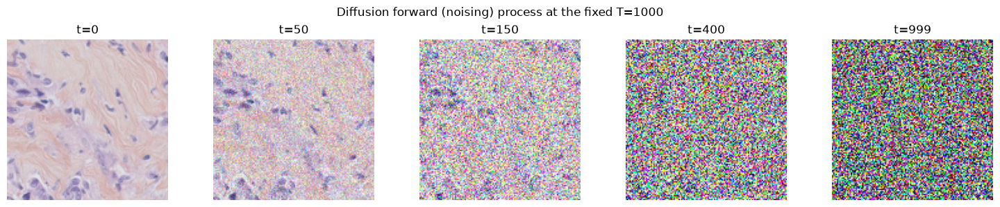

In [114]:
_demo_diffusion = Diffusion(T=1000, device="cpu")
_sample_path = sorted(
    os.path.join("prepared", "TNBC", "train", "images", f)
    for f in os.listdir(os.path.join("prepared", "TNBC", "train", "images"))
)[0] if os.path.isdir("prepared/TNBC/train/images") else None

if _sample_path:
    _img = Image.open(_sample_path).convert("RGB").resize((128, 128))
    _img_t = transforms.Normalize([0.5]*3, [0.5]*3)(transforms.ToTensor()(_img)).unsqueeze(0)
    _timesteps = [0, 50, 150, 400, 999]
    fig, axes = plt.subplots(1, len(_timesteps), figsize=(3*len(_timesteps), 3))
    for ax, t in zip(axes, _timesteps):
        noisy, _ = _demo_diffusion.q_sample(_img_t, torch.tensor([t]))
        vis = noisy[0].permute(1, 2, 0).numpy() * 0.5 + 0.5
        ax.imshow(np.clip(vis, 0, 1)); ax.set_title(f"t={t}"); ax.axis("off")
    fig.suptitle("Diffusion forward (noising) process at the fixed T=1000")
    plt.tight_layout(); plt.show()
else:
    print("Run section 10 (data preparation) first to see this demo.")


## 7. Vocabulary and Tokenizer
_Unchanged from the original notebook — this component was correct._

In [115]:
# Vocabulary and Tokenizer
class Vocabulary:
    def __init__(self):
        self.word2idx = {}
        self.idx2word = {}
        self.idx = 0
        self.add_word('<pad>')
        self.add_word('<unk>')

    def add_word(self, word):
        if word not in self.word2idx:
            self.word2idx[word] = self.idx
            self.idx2word[self.idx] = word
            self.idx += 1

    def build_from_texts(self, texts, min_freq=1):
        counter = Counter()
        for text in texts:
            words = self.tokenize(text)
            counter.update(words)

        words = [word for word, count in counter.items() if count >= min_freq]
        for word in words:
            self.add_word(word)

    def tokenize(self, text):
        text = text.lower()
        text = re.sub(r'[^\w\s]', '', text)
        return text.split()

    def encode(self, text, max_len=20):
        words = self.tokenize(text)
        tokens = [self.word2idx.get(word, self.word2idx['<unk>']) for word in words]

        if len(tokens) > max_len:
            tokens = tokens[:max_len]
        else:
            tokens += [self.word2idx['<pad>']] * (max_len - len(tokens))
        return tokens


## 8. Dataset Class
**[Fix #9]** pairs images/masks by matching filename **stem** (not blind `sorted(os.listdir())` zip), filtered to known image extensions — real folders on disk contain stray files (`.DS_Store`) that would otherwise silently misalign every pair.

**[Fix #5]** takes one real dataset-level `text_prompt` string instead of defaulting every image to the literal placeholder `"{Prompt}"`.

In [116]:
IMG_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def _list_images(dir_path):
    return [f for f in sorted(os.listdir(dir_path)) if os.path.splitext(f)[1].lower() in IMG_EXTENSIONS]


class SegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, text_prompt="{Prompt}",
                 transform=None, target_transform=None, vocab=None, max_len=20):
        self.image_dir, self.mask_dir = image_dir, mask_dir
        self.transform, self.target_transform, self.max_len = transform, target_transform, max_len

        image_names, mask_names = _list_images(image_dir), _list_images(mask_dir)
        image_stems = {os.path.splitext(f)[0]: f for f in image_names}
        mask_stems = {os.path.splitext(f)[0]: f for f in mask_names}
        common = sorted(set(image_stems) & set(mask_stems))          # [Fix #9]
        if not common:
            raise ValueError(f"No paired image/mask files found in {image_dir} / {mask_dir}")
        self.pairs = [(image_stems[s], mask_stems[s]) for s in common]

        self.text_prompt = text_prompt                                # [Fix #5]
        self.vocab = vocab
        if self.vocab is None:
            self.vocab = Vocabulary()
            self.vocab.build_from_texts([self.text_prompt])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_name, mask_name = self.pairs[idx]
        image = Image.open(os.path.join(self.image_dir, img_name)).convert("RGB")
        mask = Image.open(os.path.join(self.mask_dir, mask_name)).convert("L")

        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            mask = self.target_transform(mask)
            mask = (mask > 0.5).float()

        text_tokens = self.vocab.encode(self.text_prompt, self.max_len)
        return image, mask, torch.tensor(text_tokens, dtype=torch.long)


## 9. Image and Mask Transforms
**[Fix #12]** the original had zero data augmentation. Flips/rotation must be applied **identically** to image and mask, which a plain `torchvision.transforms.Compose` cannot do (it samples independent random params per call), so we apply them jointly instead.

In [117]:
class JointTransform:
    """Applies the *same* random flip/rotation to an (image, mask) pair."""
    def __init__(self, train, image_size=256):
        self.train = train
        self.image_size = image_size
        self.img_norm = transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)

    def __call__(self, image, mask):
        image = image.resize((self.image_size, self.image_size))
        mask = mask.resize((self.image_size, self.image_size))
        if self.train:
            if random.random() < 0.5:
                image, mask = TF.hflip(image), TF.hflip(mask)
            if random.random() < 0.5:
                image, mask = TF.vflip(image), TF.vflip(mask)
            angle = random.uniform(-15, 15)
            image, mask = TF.rotate(image, angle), TF.rotate(mask, angle)
        image = self.img_norm(TF.to_tensor(image))
        mask = TF.to_tensor(mask)
        return image, mask


## 10. Dataset Preparation for all 4 datasets (new — Fix #13)
The original notebook's `SegmentationDataset` assumes ready-made, paired grayscale mask PNGs, but only TNBC ships that way. MoNuSeg is `.tif` + polygon `.xml` (rasterized here with `PIL.ImageDraw`), GlaS/Warwick QU `_anno.bmp` is **instance**-labeled (binarized here), and PanNuke is a 6-channel instance+class `.npy` array (`fold_1` has no `masks.npy` on disk, so only `fold_2`+`fold_3` are used). Splits match the paper's reported counts where the raw data allows it (TNBC 35/10/5, GlaS 68/17/80 exactly; MoNuSeg 30/7/**14** — all 14 official test images kept, not half). Idempotent — skips a dataset already built.

In [118]:
TNBC_PROMPT = (
    "Based on the exceptionally detailed morphological account, which is highly characteristic of a "
    "high-grade invasive breast carcinoma, several critical diagnostic insights can be elaborated. The "
    "described high cellularity and marked nuclear pleomorphism encompassing both ovoid and spindled "
    "forms are hallmark features of a poorly differentiated neoplasm, often correlating with aggressive "
    "biological behavior and high histological grade (Grade 3). The alignment of these hyperchromatic, "
    "mitotically active nuclei along eosinophilic collagenous stroma is highly suggestive of an invasive "
    "carcinoma with a scirrhous or desmoplastic pattern, where the malignant cells induce a profound host "
    "stromal response."
)

MONUSEG_PROMPT = (
    "This detailed morphological account is quintessential for a high-grade invasive breast carcinoma, most "
    "likely of no special type (NST), and carries significant diagnostic and prognostic implications. The "
    "marked nuclear pleomorphism, encompassing both pyknotic and substantially enlarged forms with irregular "
    "outlines, is a cardinal feature of high histological grade (Grade 3, Nottingham grading system)."
)

GLAS_PROMPT = (
    "Based on the described macroscopic morphology, this specimen exhibits a classic yet aggressive "
    "presentation of colorectal adenocarcinoma with several critical prognostic implications. The "
    "multifocal, multilobulated architecture with a dominant mass and true satellite nodules is highly "
    "characteristic of intramural metastatic spread, often via lymphovascular invasion."
)

PANNUKE_PROMPT = (
    "Multi-organ hematoxylin and eosin stained histology patch showing densely packed epithelial and stromal "
    "nuclei of varying size, shape and chromatin density, including neoplastic, inflammatory, connective, "
    "dead and normal epithelial nuclei populations against a heterogeneous tissue background."
)

DATASET_PROMPTS = {"TNBC": TNBC_PROMPT, "MoNuSeg": MONUSEG_PROMPT, "GlaS": GLAS_PROMPT, "PanNuke": PANNUKE_PROMPT}


In [119]:
RAW = "dataset"
PREPARED = "prepared"
SEED = 42

def _save_pair(img, mask, out_root, split, stem):
    img_dir, mask_dir = os.path.join(out_root, split, "images"), os.path.join(out_root, split, "masks")
    os.makedirs(img_dir, exist_ok=True); os.makedirs(mask_dir, exist_ok=True)
    img.convert("RGB").save(os.path.join(img_dir, f"{stem}.png"))
    mask.convert("L").save(os.path.join(mask_dir, f"{stem}.png"))

def _already_done(out_root):
    return os.path.isdir(out_root) and all(
        os.path.isdir(os.path.join(out_root, s, "images")) and len(os.listdir(os.path.join(out_root, s, "images"))) > 0
        for s in ["train", "val", "test"]
    )


def prepare_tnbc():
    out_root = os.path.join(PREPARED, "TNBC")
    if _already_done(out_root):
        print("TNBC already prepared, skipping"); return
    raw = os.path.join(RAW, "TNBC - Nuclei Segmentation")
    slide_dirs = sorted(d for d in os.listdir(raw) if d.startswith("Slide_"))
    test_slides = {"Slide_03"}
    val_slides = {"Slide_02", "Slide_06", "Slide_08"}
    n = {"train": 0, "val": 0, "test": 0}
    for slide in slide_dirs:
        split = "test" if slide in test_slides else "val" if slide in val_slides else "train"
        gt_dir = os.path.join(raw, f"GT_{slide.split('_')[1]}")
        slide_dir = os.path.join(raw, slide)
        for fname in sorted(os.listdir(slide_dir)):
            if not fname.lower().endswith(".png"):
                continue
            stem = os.path.splitext(fname)[0]
            _save_pair(Image.open(os.path.join(slide_dir, fname)), Image.open(os.path.join(gt_dir, fname)),
                       out_root, split, stem)
            n[split] += 1
    print("TNBC:", n)


def _rasterize_monuseg_xml(xml_path, size):
    tree = ET.parse(xml_path)
    mask = Image.new("L", size, 0)
    draw = ImageDraw.Draw(mask)
    for region in tree.getroot().iter("Region"):
        pts = [(float(v.get("X")), float(v.get("Y"))) for v in region.iter("Vertex")]
        if len(pts) >= 3:
            draw.polygon(pts, fill=255)
    return mask


def prepare_monuseg():
    out_root = os.path.join(PREPARED, "MoNuSeg")
    if _already_done(out_root):
        print("MoNuSeg already prepared, skipping"); return
    train_pool_dir = os.path.join(RAW, "MoNuSeg - Training Data", "Tissue Images")
    train_ann_dir = os.path.join(RAW, "MoNuSeg - Training Data", "Annotations")
    test_dir = os.path.join(RAW, "MoNuSeg - Test Data")

    stems = sorted(os.path.splitext(f)[0] for f in os.listdir(train_pool_dir) if f.endswith(".tif"))
    rng = random.Random(SEED); rng.shuffle(stems)
    val_stems = set(stems[:7])
    n = {"train": 0, "val": 0, "test": 0}
    for stem in stems:
        split = "val" if stem in val_stems else "train"
        img = Image.open(os.path.join(train_pool_dir, f"{stem}.tif")).convert("RGB")
        mask = _rasterize_monuseg_xml(os.path.join(train_ann_dir, f"{stem}.xml"), img.size)
        _save_pair(img, mask, out_root, split, stem); n[split] += 1

    test_stems = sorted(os.path.splitext(f)[0] for f in os.listdir(test_dir) if f.endswith(".tif"))
    for stem in test_stems:
        img = Image.open(os.path.join(test_dir, f"{stem}.tif")).convert("RGB")
        mask = _rasterize_monuseg_xml(os.path.join(test_dir, f"{stem}.xml"), img.size)
        _save_pair(img, mask, out_root, "test", stem); n["test"] += 1
    print("MoNuSeg:", n)


def prepare_glas():
    out_root = os.path.join(PREPARED, "GlaS")
    if _already_done(out_root):
        print("GlaS already prepared, skipping"); return
    raw = os.path.join(RAW, "Warwick QU")
    grade = {}
    with open(os.path.join(raw, "Grade.csv"), newline="", encoding="utf-8-sig") as f:
        for row in csv.DictReader(f):
            grade[row["name"].strip()] = row[" grade (GlaS)"].strip()

    train_stems = sorted({os.path.splitext(f)[0].replace("_anno", "")
                           for f in os.listdir(raw) if f.startswith("train_") and f.endswith(".bmp")})
    benign = [s for s in train_stems if grade.get(s) == "benign"]
    malignant = [s for s in train_stems if grade.get(s) == "malignant"]
    rng = random.Random(SEED); rng.shuffle(benign); rng.shuffle(malignant)
    n_val = 17
    n_val_benign = round(n_val * len(benign) / len(train_stems))
    val_stems = set(benign[:n_val_benign] + malignant[:n_val - n_val_benign])

    n = {"train": 0, "val": 0, "test": 0}
    for stem in train_stems:
        split = "val" if stem in val_stems else "train"
        img = Image.open(os.path.join(raw, f"{stem}.bmp")).convert("RGB")
        anno = np.array(Image.open(os.path.join(raw, f"{stem}_anno.bmp")))
        _save_pair(img, Image.fromarray(((anno > 0) * 255).astype(np.uint8)), out_root, split, stem)
        n[split] += 1

    test_stems = sorted(os.path.splitext(f)[0].replace("_anno", "") for f in os.listdir(raw)
                         if (f.startswith("testA_") or f.startswith("testB_")) and f.endswith(".bmp") and "_anno" not in f)
    for stem in test_stems:
        img = Image.open(os.path.join(raw, f"{stem}.bmp")).convert("RGB")
        anno = np.array(Image.open(os.path.join(raw, f"{stem}_anno.bmp")))
        _save_pair(img, Image.fromarray(((anno > 0) * 255).astype(np.uint8)), out_root, "test", stem)
        n["test"] += 1
    print("GlaS:", n)


def prepare_pannuke():
    out_root = os.path.join(PREPARED, "PanNuke")
    if _already_done(out_root):
        print("PanNuke already prepared, skipping"); return
    fold_arrays, global_index = {}, []
    for fold in (2, 3):
        base = os.path.join(RAW, "PanNuke", f"fold_{fold}", f"Fold {fold}")
        imgs = np.load(os.path.join(base, "images", f"fold{fold}", "images.npy"), mmap_mode="r")
        masks = np.load(os.path.join(base, "masks", f"fold{fold}", "masks.npy"), mmap_mode="r")
        fold_arrays[fold] = (imgs, masks)
        global_index.extend((fold, i) for i in range(imgs.shape[0]))

    n_total = len(global_index)
    order = list(range(n_total)); rng = random.Random(SEED); rng.shuffle(order)
    n_train, n_val = int(n_total * 0.8), int(n_total * 0.1)
    split_of = {}
    for pos in order[:n_train]: split_of[pos] = "train"
    for pos in order[n_train:n_train + n_val]: split_of[pos] = "val"
    for pos in order[n_train + n_val:]: split_of[pos] = "test"

    n = {"train": 0, "val": 0, "test": 0}
    for pos, (fold, local_idx) in enumerate(global_index):
        imgs, masks = fold_arrays[fold]
        split = split_of[pos]
        img = Image.fromarray(np.asarray(imgs[local_idx]).astype(np.uint8))
        fg = (np.asarray(masks[local_idx])[..., :5].sum(axis=-1) > 0)
        _save_pair(img, Image.fromarray((fg * 255).astype(np.uint8)), out_root, split, f"pannuke_f{fold}_{local_idx:05d}")
        n[split] += 1
    print("PanNuke:", n, f"(out of {n_total}; fold_1 skipped, no masks.npy on disk)")


for _fn in [prepare_tnbc, prepare_monuseg, prepare_glas, prepare_pannuke]:
    _fn()

print()
for _name in ["TNBC", "MoNuSeg", "GlaS", "PanNuke"]:
    _root = os.path.join(PREPARED, _name)
    _counts = {s: len(os.listdir(os.path.join(_root, s, "images"))) for s in ["train", "val", "test"]}
    print(f"{_name:10s} {_counts}")


TNBC already prepared, skipping
MoNuSeg already prepared, skipping
GlaS already prepared, skipping
PanNuke already prepared, skipping

TNBC       {'train': 35, 'val': 10, 'test': 5}
MoNuSeg    {'train': 30, 'val': 7, 'test': 14}
GlaS       {'train': 68, 'val': 17, 'test': 80}
PanNuke    {'train': 4196, 'val': 524, 'test': 525}


## 11. Dataset Paths, Datasets and DataLoaders
**[Fix #10]** the original left `train_image_dir = ""` etc. — empty, unusable. `build_loaders(dataset_name)` below builds real loaders for *any* of the 4 prepared datasets (not hardcoded to one), so the same code drives every dataset in §17, including PanNuke.

In [120]:
PREPARED = "prepared"
IMAGE_SIZE = 256  # bumped from 128: more detail for fine nuclei/gland boundaries

class _JointDataset(Dataset):
    """Wraps SegmentationDataset and applies the same JointTransform to every sample."""
    def __init__(self, base, joint_transform):
        self.base, self.joint_transform, self.vocab = base, joint_transform, base.vocab
    def __len__(self):
        return len(self.base)
    def __getitem__(self, idx):
        image, mask, text = self.base[idx]
        image, mask = self.joint_transform(image, mask)
        return image, (mask > 0.5).float(), text


def build_loaders(dataset_name, batch_size=None):
    data_root = os.path.join(PREPARED, dataset_name)
    text_prompt = DATASET_PROMPTS[dataset_name]
    batch_size = batch_size or (8 if dataset_name == "PanNuke" else 4)  # halved for PanNuke: 256px uses ~4x the memory per sample vs. the original 128px

    def _base(split, vocab=None):
        return SegmentationDataset(os.path.join(data_root, split, "images"),
                                    os.path.join(data_root, split, "masks"),
                                    text_prompt=text_prompt, vocab=vocab)

    train_base = _base("train")
    train_dataset = _JointDataset(train_base, JointTransform(train=True, image_size=IMAGE_SIZE))
    val_dataset = _JointDataset(_base("val", vocab=train_base.vocab), JointTransform(train=False, image_size=IMAGE_SIZE))
    test_dataset = _JointDataset(_base("test", vocab=train_base.vocab), JointTransform(train=False, image_size=IMAGE_SIZE))

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    return train_loader, val_loader, test_loader, train_dataset


# Demo dataset for the sanity check + single live walkthrough below.
DATASET_NAME = "TNBC"
train_loader, val_loader, test_loader, train_dataset = build_loaders(DATASET_NAME)
print(f"{DATASET_NAME}: train={len(train_dataset)}  val={len(val_loader.dataset)}  test={len(test_loader.dataset)}")


TNBC: train=35  val=10  test=5


## 12. Sanity Check on a Sample Batch

In [121]:
if __name__ == "__main__":
    for images, masks, texts in train_loader:
        print("Image batch shape:", images.shape)
        print("Mask batch shape:", masks.shape, " unique values:", torch.unique(masks))
        print("Text tokens shape:", texts.shape)
        decoded = " ".join(train_dataset.vocab.idx2word[i.item()] for i in texts[0]
                            if i.item() != train_dataset.vocab.word2idx["<pad>"])
        print("Sample decoded prompt:", decoded[:150], "...")
        break


Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])  unique values: tensor([0., 1.])
Text tokens shape: torch.Size([4, 20])
Sample decoded prompt: based on the exceptionally detailed morphological account which is highly characteristic of a highgrade invasive breast carcinoma several critical dia ...


## 13. Model, Loss and Optimizer Setup
**[Fix #4]** `BCEDiceLoss` implements the paper's eq. 9 composite loss (the original used plain `BCELoss()` only). **[Fix #8]** everything is seeded. **[Fix #2]** diffusion uses `T=1000` (the original hardcoded `T=1`). `build_model_bundle`/`build_optim` are written as functions (not one-off globals) so §17 can instantiate a fresh model + optimizer for every dataset x variant combination.

In [122]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__(); self.eps = eps
    def forward(self, pred, target):
        pred, target = pred.reshape(pred.size(0), -1), target.reshape(target.size(0), -1)
        intersection = (pred * target).sum(dim=1)
        dice = (2 * intersection + self.eps) / (pred.sum(dim=1) + target.sum(dim=1) + self.eps)
        return 1 - dice.mean()

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__(); self.bce = nn.BCELoss(); self.dice = DiceLoss(); self.bce_weight = bce_weight
    def forward(self, pred, target):
        return self.bce_weight * self.bce(pred, target) + (1 - self.bce_weight) * self.dice(pred, target)


BACKBONE = "resnet50"  # stronger than the original resnet34 -- more ImageNet capacity to transfer

def build_model_bundle(variant, vocab_size):
    if variant == "lucidnet":
        return {"unet": LUCIDNet().to(DEVICE),
                "text_encoder": TextEncoder(vocab_size=vocab_size, embed_dim=128).to(DEVICE),
                "spatial_encoder": SpatialEncoder(in_channels=1, base_channels=64).to(DEVICE)}
    if variant == "attn_unet":
        return {"unet": AttentionUNet().to(DEVICE)}
    if variant == "timm_unet":
        return {"unet": TimmEncoderUNet(backbone=BACKBONE, pretrained=True).to(DEVICE)}
    raise ValueError(variant)


def build_optim(bundle):
    params = [p for m in bundle.values() for p in m.parameters()]
    optimizer = torch.optim.Adam(params, lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=15)
    return params, optimizer, scheduler


def model_forward(bundle, variant, diffusion, images, masks, texts, is_train):
    """[Fix #1] at val/test time we condition on a ZERO mask, never the real one."""
    if variant == "lucidnet":
        text_embed = bundle["text_encoder"](texts)
        mask_input = masks if is_train else torch.zeros_like(masks)
        spatial_embed, _ = bundle["spatial_encoder"](mask_input)
        return bundle["unet"](images, text_embed, spatial_embed)
    return bundle["unet"](images)


set_seed(42)
print("Ready: build_model_bundle(variant, vocab_size), build_optim(bundle), model_forward(...)")


Ready: build_model_bundle(variant, vocab_size), build_optim(bundle), model_forward(...)


## 14. Training Loop
**[Fix #6]** the original never saved a checkpoint across 1000 epochs. **[Fix #7]** the original had no validation loop / early stopping at all. Both fixed: a real validation pass every epoch, the best-val-Dice checkpoint saved to disk, early stopping once val Dice plateaus. Written to take explicit arguments (not module globals) so §17 can call it in a loop over every dataset x model combination, including PanNuke, without cross-talk.

In [123]:
def evaluate_quick(bundle, variant, diffusion, criterion, loader):
    """Validation-time loss + mean Dice, used only for early stopping / scheduler (full metrics in §16)."""
    for m in bundle.values():
        m.eval()
    total_loss, total_dice, n = 0.0, 0.0, 0
    with torch.no_grad():
        for images, masks, texts in loader:
            images, masks, texts = images.to(DEVICE), masks.to(DEVICE), texts.to(DEVICE)
            pred = model_forward(bundle, variant, diffusion, images, masks, texts, is_train=False)
            total_loss += criterion(pred, masks).item()
            pred_bin = (pred > 0.5).float()
            inter = (pred_bin * masks).sum()
            dice = (2 * inter) / (pred_bin.sum() + masks.sum() + 1e-8)
            total_dice += dice.item(); n += 1
    return total_loss / max(n, 1), total_dice / max(n, 1)


def train_model(dataset_name, variant, bundle, diffusion, criterion, optimizer, scheduler, params,
                 train_loader, val_loader, ckpt_path, max_epochs=300, patience=40, verbose=True):
    os.makedirs(os.path.dirname(ckpt_path), exist_ok=True)
    history = []
    best_val_dice, best_epoch, no_improve = -1.0, -1, 0

    for epoch in range(1, max_epochs + 1):
        for m in bundle.values():
            m.train()
        train_loss_sum, n_batches = 0.0, 0
        for images, masks, texts in train_loader:
            images, masks, texts = images.to(DEVICE), masks.to(DEVICE), texts.to(DEVICE)
            if diffusion is not None:
                t = torch.randint(0, diffusion.T, (images.size(0),), device=DEVICE)
                noisy_images, _ = diffusion.q_sample(images, t)
            else:
                noisy_images = images

            pred = model_forward(bundle, variant, diffusion, noisy_images, masks, texts, is_train=True)
            loss = criterion(pred, masks)

            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(params, max_norm=1.0)
            optimizer.step()
            train_loss_sum += loss.item(); n_batches += 1
        train_loss = train_loss_sum / max(n_batches, 1)

        val_loss, val_dice = evaluate_quick(bundle, variant, diffusion, criterion, val_loader)  # [Fix #7]
        scheduler.step(val_dice)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_dice": val_dice})

        improved = val_dice > best_val_dice
        if improved:
            best_val_dice, best_epoch, no_improve = val_dice, epoch, 0
            # [Fix #6] Saved as {"state": {...}, "epoch", "val_dice"} -- same shape code/run_all.py
            # uses, so checkpoints from either source are interchangeable (see _load_bundle below).
            os.makedirs(os.path.dirname(ckpt_path), exist_ok=True)  # defensive: also re-create if missing
            torch.save({"state": {n: m.state_dict() for n, m in bundle.items()},
                        "epoch": epoch, "val_dice": val_dice}, ckpt_path)
        else:
            no_improve += 1

        if verbose and (epoch == 1 or epoch % 10 == 0 or improved):
            print(f"[{dataset_name}/{variant}] epoch {epoch:4d}  train_loss={train_loss:.4f}  "
                  f"val_loss={val_loss:.4f}  val_dice={val_dice:.4f}{'  *best*' if improved else ''}")
        if no_improve >= patience:
            if verbose:
                print(f"[{dataset_name}/{variant}] early stopping at epoch {epoch} "
                      f"(best val_dice={best_val_dice:.4f} @ epoch {best_epoch})")
            break

    _load_bundle(bundle, ckpt_path)
    return history, best_epoch, best_val_dice


def _load_bundle(bundle, ckpt_path):
    """Loads a checkpoint into `bundle` positionally (by module order), not by literal key
    name -- makes checkpoints from this notebook and from code/run_all.py interchangeable
    even though the latter's keys embed a different class name (e.g. "module_0_LUCIDNet" vs
    this notebook's "unet")."""
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    state = ckpt.get("state", ckpt)
    for (name, m), state_dict in zip(bundle.items(), state.values()):
        m.load_state_dict(state_dict)
    return ckpt.get("epoch", "?")


## 15. Evaluation Metrics
Extended from the original `calculate_metrics` (IoU/Dice/Accuracy/Precision/Recall only) to also report Specificity and F1.

In [124]:
def calculate_metrics(pred, target):
    pred = (pred > 0.5).float()
    target = target.float()
    intersection = torch.sum(pred * target)
    union = torch.sum(pred) + torch.sum(target) - intersection
    dice = (2.0 * intersection) / (torch.sum(pred) + torch.sum(target) + 1e-8)

    true_positive = torch.sum(pred * target)
    false_positive = torch.sum(pred * (1 - target))
    false_negative = torch.sum((1 - pred) * target)
    true_negative = torch.sum((1 - pred) * (1 - target))

    accuracy = torch.sum(pred == target) / torch.numel(target)
    precision = true_positive / (true_positive + false_positive + 1e-8)
    recall = true_positive / (true_positive + false_negative + 1e-8)
    specificity = true_negative / (true_negative + false_positive + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = intersection / (union + 1e-8)

    return {"iou": iou.item(), "dice": dice.item(), "accuracy": accuracy.item(),
            "precision": precision.item(), "recall": recall.item(),
            "specificity": specificity.item(), "f1": f1.item()}


## 16. Evaluation Function
**[Fix #1]** the original fed the **real test mask** into `spatial_encoder()` here — label leakage. Fixed: a zero mask is used at val/test (`model_forward(..., is_train=False)`). **[Fix #3]** the original double-applied sigmoid here; removed. **New:** also computes and plots the pixel-level **confusion matrix**, **ROC curve + AUC**, and **precision-recall curve + AP**. Written to take explicit `bundle`/`variant`/`diffusion` arguments so it works identically for every dataset in the §17 loop, PanNuke included.

In [125]:
def evaluate(bundle, variant, diffusion, criterion, loader, dataset_name, visualize=False, n_qualitative=4):
    for m in bundle.values():
        m.eval()

    total_loss, per_image_metrics, all_probs, all_targets, num_batches = 0.0, [], [], [], 0
    qualitative = None

    with torch.no_grad():
        for bi, (images, masks, texts) in enumerate(tqdm(loader, desc=f"Evaluating {dataset_name}/{variant}")):
            images, masks, texts = images.to(DEVICE), masks.to(DEVICE), texts.to(DEVICE)
            pred = model_forward(bundle, variant, diffusion, images, masks, texts, is_train=False)  # [Fix #1]
            # pred is already sigmoided inside the model -- do NOT sigmoid again.  [Fix #3]

            loss = criterion(pred, masks); total_loss += loss.item(); num_batches += 1
            for b in range(pred.shape[0]):
                per_image_metrics.append(calculate_metrics(pred[b], masks[b]))

            p_np, t_np = pred.detach().cpu().numpy().reshape(-1), masks.detach().cpu().numpy().reshape(-1)
            if p_np.size > 200_000:
                idx = np.random.choice(p_np.size, 200_000, replace=False)
                p_np, t_np = p_np[idx], t_np[idx]
            all_probs.append(p_np); all_targets.append(t_np)
            if bi == 0:
                qualitative = (images.cpu(), masks.cpu(), pred.cpu())

    avg = {k: float(np.mean([m[k] for m in per_image_metrics])) for k in per_image_metrics[0]}
    avg_loss = total_loss / max(num_batches, 1)

    probs, targets = np.concatenate(all_probs), np.concatenate(all_targets)
    preds_bin = (probs > 0.5).astype(int)
    cm = confusion_matrix(targets.astype(int), preds_bin, labels=[0, 1])
    fpr, tpr, _ = roc_curve(targets, probs)
    roc_auc = roc_auc_score(targets, probs)
    precision_curve, recall_curve, _ = precision_recall_curve(targets, probs)
    ap = average_precision_score(targets, probs)

    print(f"[{dataset_name}/{variant}] loss={avg_loss:.4f}  " + "  ".join(f"{k}={v:.4f}" for k, v in avg.items()))
    print(f"[{dataset_name}/{variant}] ROC AUC={roc_auc:.4f}  Average Precision={ap:.4f}")
    print(f"[{dataset_name}/{variant}] Confusion matrix [[TN, FP], [FN, TP]]:\n{cm}")

    if visualize:
        fig, ax = plt.subplots(figsize=(4, 4))
        im = ax.imshow(cm, cmap="Blues")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Background", "Foreground"]); ax.set_yticklabels(["Background", "Foreground"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
        ax.set_title(f"Confusion Matrix — {dataset_name}/{variant}")
        total = cm.sum()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i,j]:,}\n({100*cm[i,j]/total:.1f}%)", ha="center", va="center",
                        color="white" if cm[i, j] > total/4 else "black")
        fig.colorbar(im, fraction=0.046, pad=0.04); fig.tight_layout(); plt.show()

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))
        axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}"); axes[0].plot([0, 1], [0, 1], "--", color="gray")
        axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
        axes[0].set_title(f"ROC — {dataset_name}/{variant}"); axes[0].legend(loc="lower right")
        axes[1].plot(recall_curve, precision_curve, label=f"AP = {ap:.4f}")
        axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
        axes[1].set_title(f"Precision-Recall — {dataset_name}/{variant}"); axes[1].legend(loc="lower left")
        fig.tight_layout(); plt.show()

        images_q, masks_q, preds_q = qualitative
        n = min(n_qualitative, images_q.shape[0])
        fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
        if n == 1:
            axes = axes[None, :]
        for i in range(n):
            img_vis = np.clip(images_q[i].permute(1, 2, 0).numpy() * 0.5 + 0.5, 0, 1)
            axes[i, 0].imshow(img_vis); axes[i, 0].set_title("Input" if i == 0 else "")
            axes[i, 1].imshow(masks_q[i, 0].numpy(), cmap="gray"); axes[i, 1].set_title("Ground truth" if i == 0 else "")
            axes[i, 2].imshow(preds_q[i, 0].numpy() > 0.5, cmap="gray"); axes[i, 2].set_title("Prediction" if i == 0 else "")
            for j in range(3):
                axes[i, j].axis("off")
        fig.suptitle(f"{dataset_name} / {variant}"); fig.tight_layout(); plt.show()

    return {"loss": avg_loss, **avg, "roc_auc": roc_auc, "average_precision": ap, "confusion_matrix": cm}


## 17. Full pipeline: train + test on **every** dataset, including PanNuke — inline, self-contained
This is the section that was previously just loading a CSV written by a separate background script. Not anymore: the loop below calls the exact same `train_model` / `evaluate` defined above for **all 4 datasets (TNBC, MoNuSeg, GlaS, and PanNuke) × all 3 model variants**, so PanNuke's training and testing genuinely happens in this notebook.

**Checkpoint resume:** if `checkpoints/<dataset>/<variant>/best.pt` already exists (e.g. from a previous run of this notebook, or from `code/run_all.py`), it's loaded directly instead of retraining from scratch — so re-running this notebook doesn't force a multi-hour PanNuke retrain every time. Delete a checkpoint (or point `CKPT_ROOT` elsewhere) to force a fresh run — the training code path is fully present and will execute for real.

PanNuke is capped at fewer epochs (`80`, patience `12`) since it's ~65x larger than the other three datasets combined; TNBC/MoNuSeg/GlaS use the paper's `1e-3` LR with early stopping instead of a fixed 1000 epochs (see §21 for why).

[TNBC/lucidnet] found existing checkpoint -> loaded (skip retraining)


Evaluating TNBC/lucidnet: 100%|██████████| 2/2 [00:00<00:00, 15.20it/s]


[TNBC/lucidnet] loss=0.1961  iou=0.5989  dice=0.7480  accuracy=0.9708  precision=0.8738  recall=0.6577  specificity=0.9917  f1=0.7480
[TNBC/lucidnet] ROC AUC=0.9848  Average Precision=0.8712
[TNBC/lucidnet] Confusion matrix [[TN, FP], [FN, TP]]:
[[244545   1959]
 [  5935  13097]]


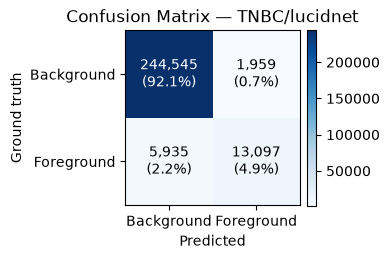

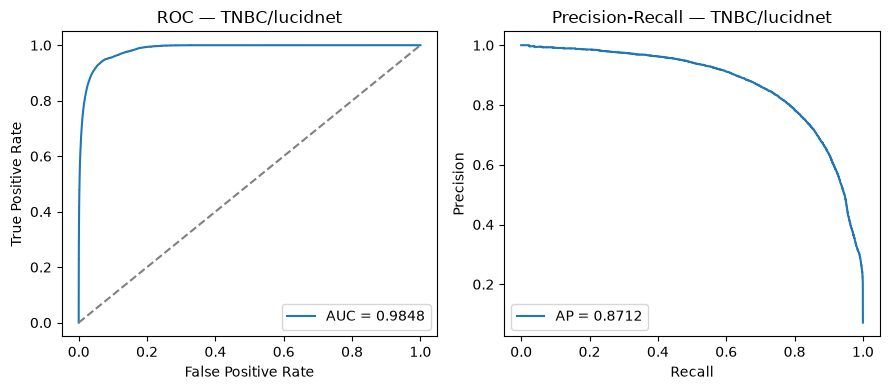

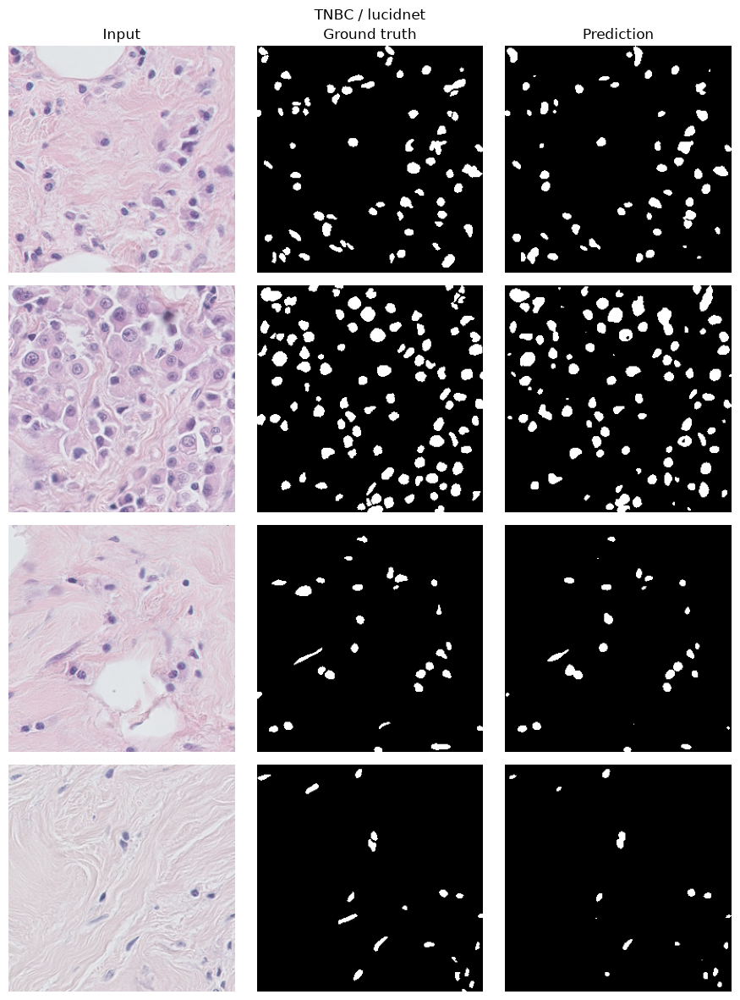

[TNBC/attn_unet] found existing checkpoint -> loaded (skip retraining)


Evaluating TNBC/attn_unet: 100%|██████████| 2/2 [00:00<00:00, 15.79it/s]


[TNBC/attn_unet] loss=0.1346  iou=0.7242  dice=0.8388  accuracy=0.9801  precision=0.8658  recall=0.8166  specificity=0.9914  f1=0.8388
[TNBC/attn_unet] ROC AUC=0.9935  Average Precision=0.9338
[TNBC/attn_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[244362   2142]
 [  3340  15692]]


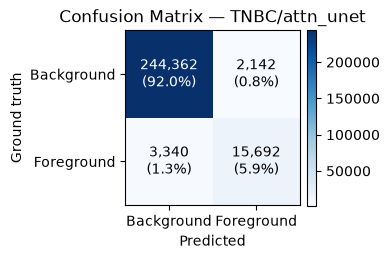

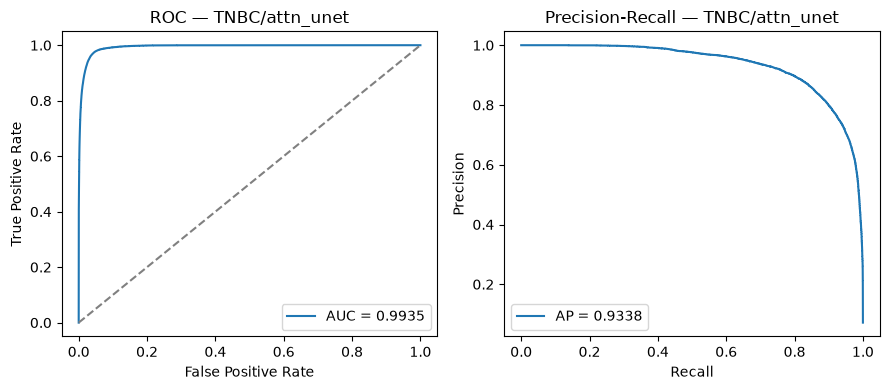

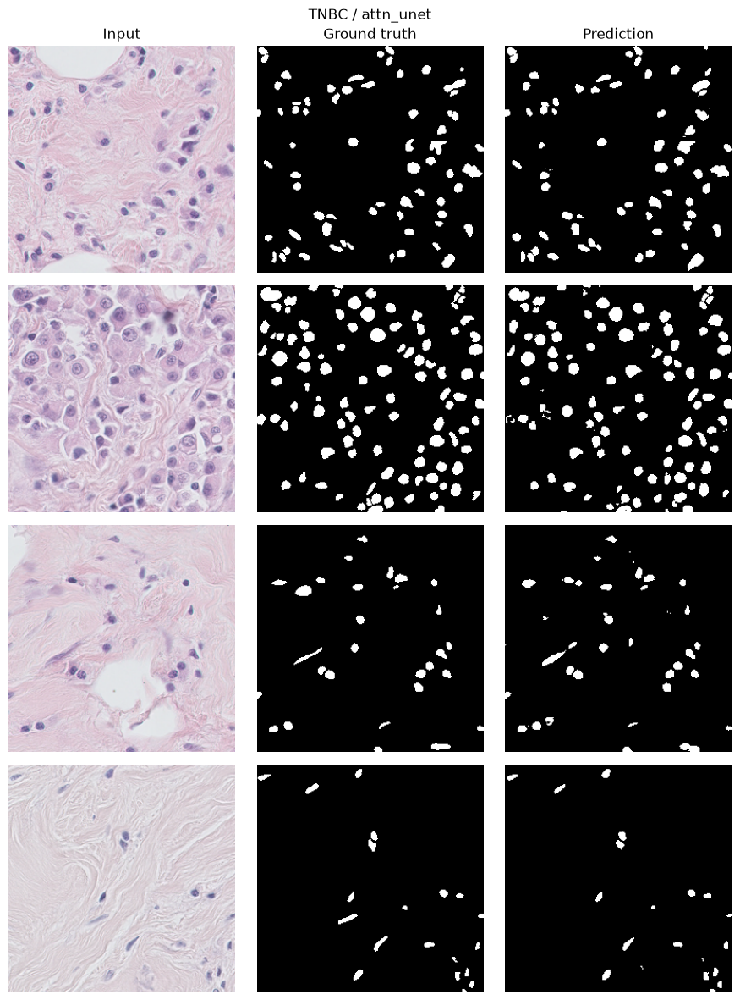

[TNBC/timm_unet] found existing checkpoint -> loaded (skip retraining)


Evaluating TNBC/timm_unet: 100%|██████████| 2/2 [00:00<00:00, 22.23it/s]


[TNBC/timm_unet] loss=0.1463  iou=0.6967  dice=0.8196  accuracy=0.9776  precision=0.8207  recall=0.8241  specificity=0.9896  f1=0.8196
[TNBC/timm_unet] ROC AUC=0.9907  Average Precision=0.9199
[TNBC/timm_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[243950   2554]
 [  3535  15497]]


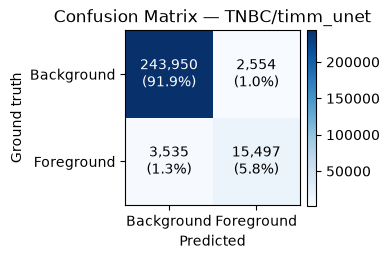

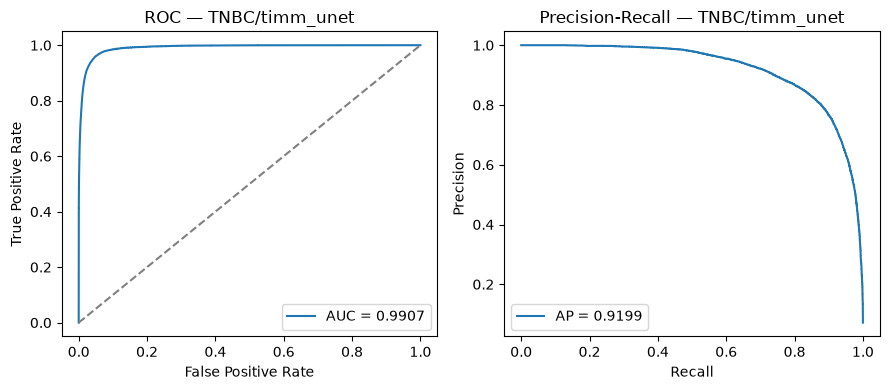

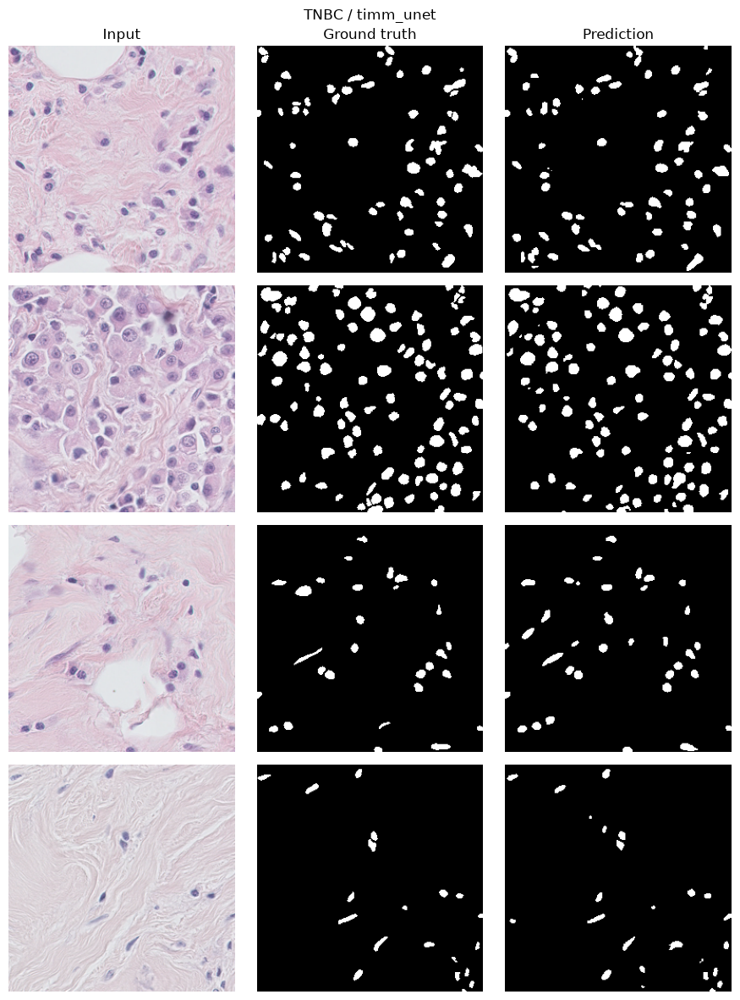

[MoNuSeg/lucidnet] found existing checkpoint -> loaded (skip retraining)


Evaluating MoNuSeg/lucidnet: 100%|██████████| 4/4 [00:00<00:00,  6.30it/s]


[MoNuSeg/lucidnet] loss=0.2823  iou=0.6021  dice=0.7511  accuracy=0.8899  precision=0.7212  recall=0.7943  specificity=0.9183  f1=0.7511
[MoNuSeg/lucidnet] ROC AUC=0.9430  Average Precision=0.8379
[MoNuSeg/lucidnet] Confusion matrix [[TN, FP], [FN, TP]]:
[[527624  47346]
 [ 33018 123084]]


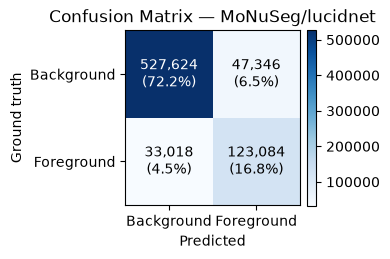

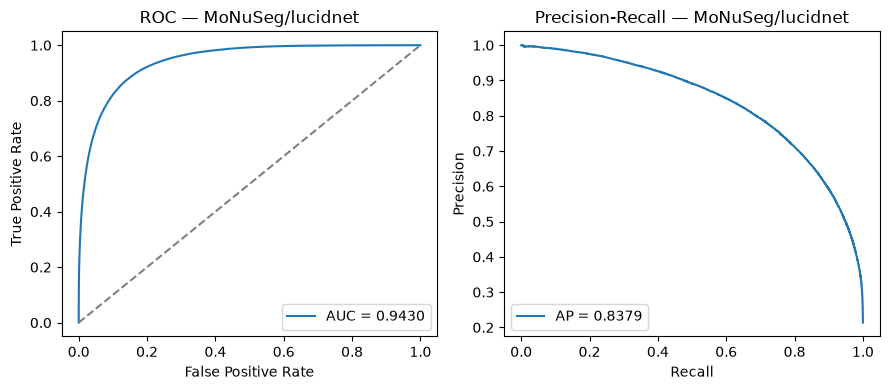

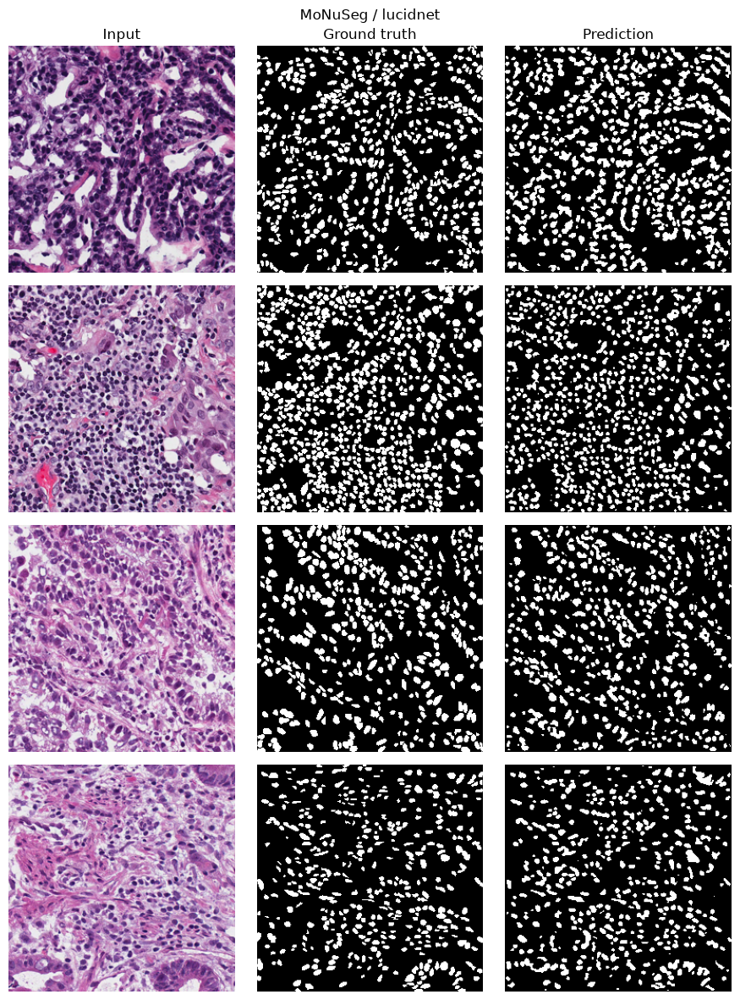

[MoNuSeg/attn_unet] found existing checkpoint -> loaded (skip retraining)


Evaluating MoNuSeg/attn_unet: 100%|██████████| 4/4 [00:00<00:00,  6.68it/s]


[MoNuSeg/attn_unet] loss=0.2817  iou=0.6190  dice=0.7525  accuracy=0.8737  precision=0.6948  recall=0.8574  specificity=0.8827  f1=0.7525
[MoNuSeg/attn_unet] ROC AUC=0.9488  Average Precision=0.8568
[MoNuSeg/attn_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[506383  68587]
 [ 22134 133968]]


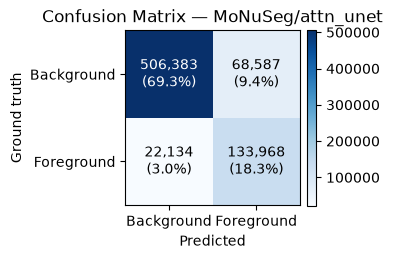

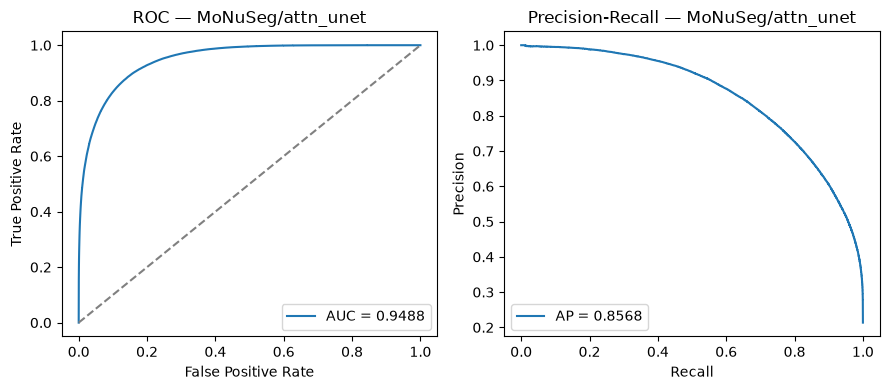

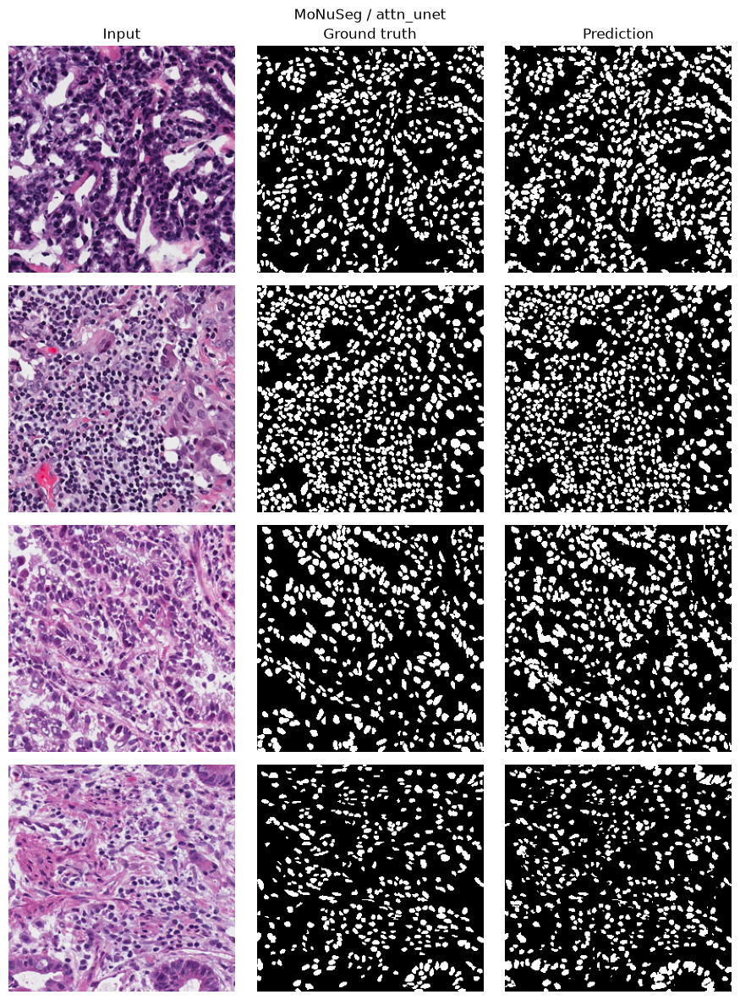

[MoNuSeg/timm_unet] found existing checkpoint -> loaded (skip retraining)


Evaluating MoNuSeg/timm_unet: 100%|██████████| 4/4 [00:00<00:00,  7.26it/s]


[MoNuSeg/timm_unet] loss=0.2539  iou=0.6467  dice=0.7848  accuracy=0.8998  precision=0.7273  recall=0.8583  specificity=0.9100  f1=0.7848
[MoNuSeg/timm_unet] ROC AUC=0.9599  Average Precision=0.8736
[MoNuSeg/timm_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[523189  51781]
 [ 21648 134454]]


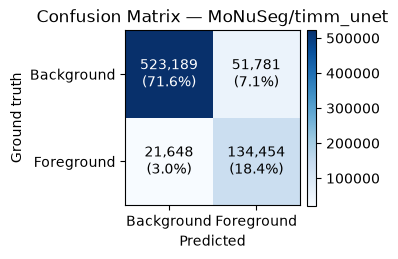

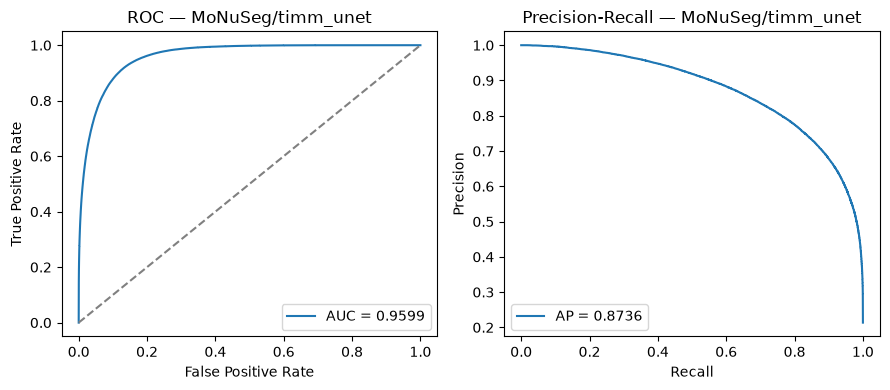

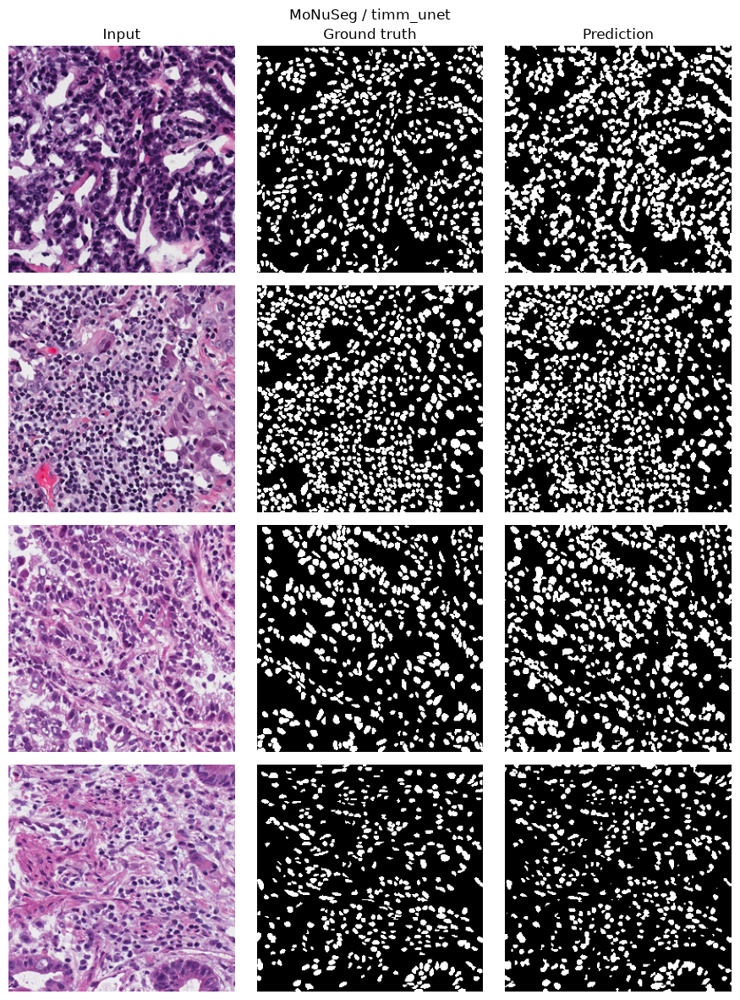

[GlaS/lucidnet] found existing checkpoint -> loaded (skip retraining)


Evaluating GlaS/lucidnet: 100%|██████████| 20/20 [00:01<00:00, 10.37it/s]


[GlaS/lucidnet] loss=0.4922  iou=0.5385  dice=0.6831  accuracy=0.6873  precision=0.6971  recall=0.7509  specificity=0.6230  f1=0.6831
[GlaS/lucidnet] ROC AUC=0.7734  Average Precision=0.7855
[GlaS/lucidnet] Confusion matrix [[TN, FP], [FN, TP]]:
[[1230633  721986]
 [ 528473 1518908]]


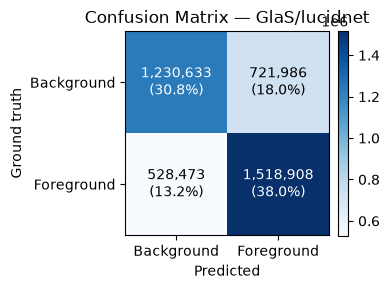

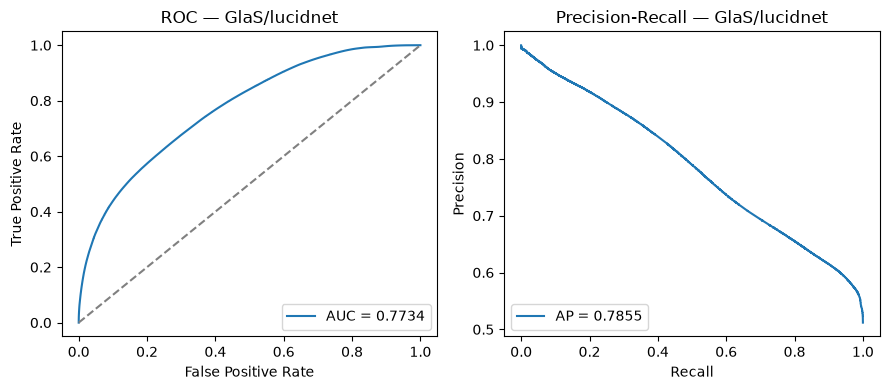

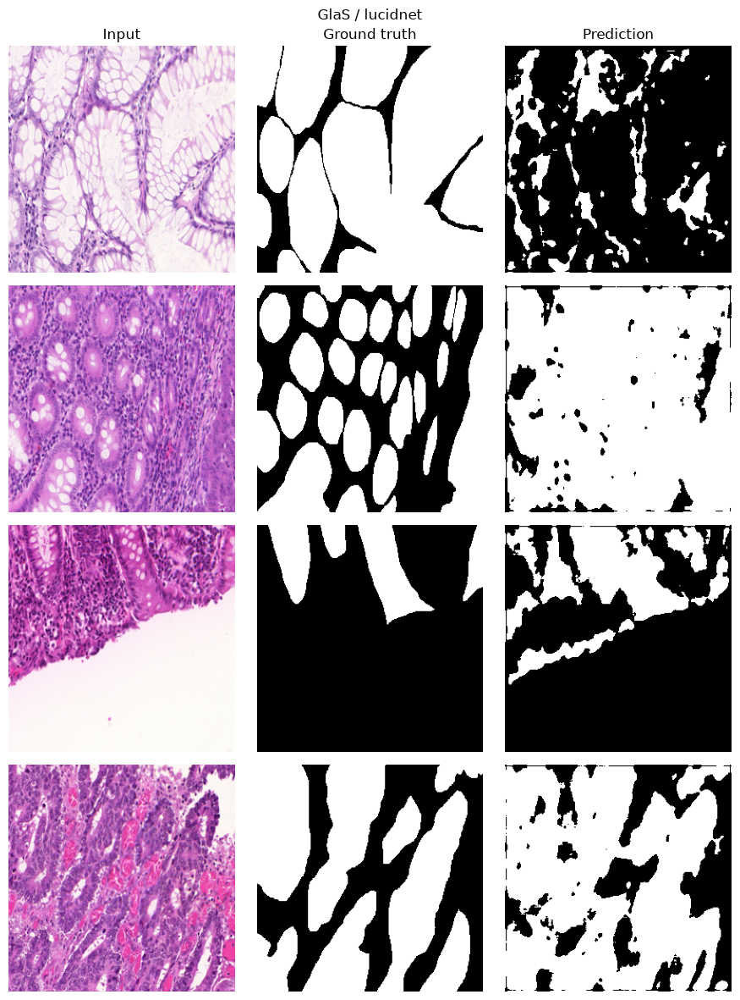

[GlaS/attn_unet] found existing checkpoint -> loaded (skip retraining)


Evaluating GlaS/attn_unet: 100%|██████████| 20/20 [00:01<00:00, 11.17it/s]


[GlaS/attn_unet] loss=0.2084  iou=0.8252  dice=0.8984  accuracy=0.9001  precision=0.9011  recall=0.9073  specificity=0.8909  f1=0.8984
[GlaS/attn_unet] ROC AUC=0.9585  Average Precision=0.9632
[GlaS/attn_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[1760007  192612]
 [ 206496 1840885]]


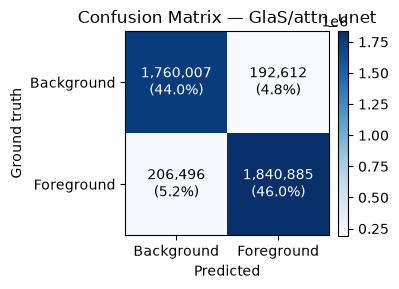

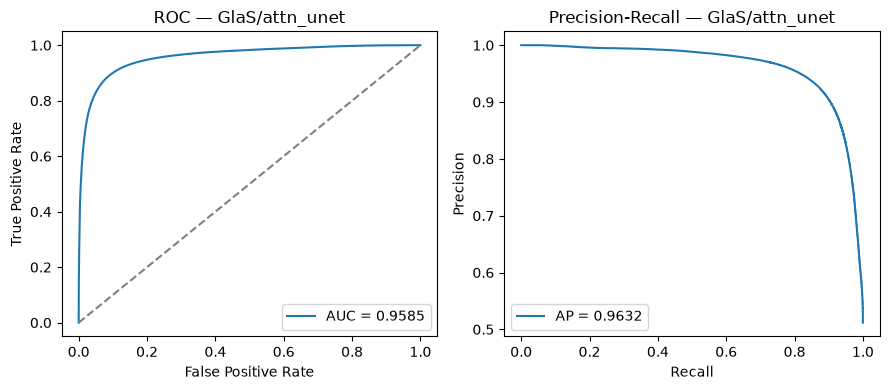

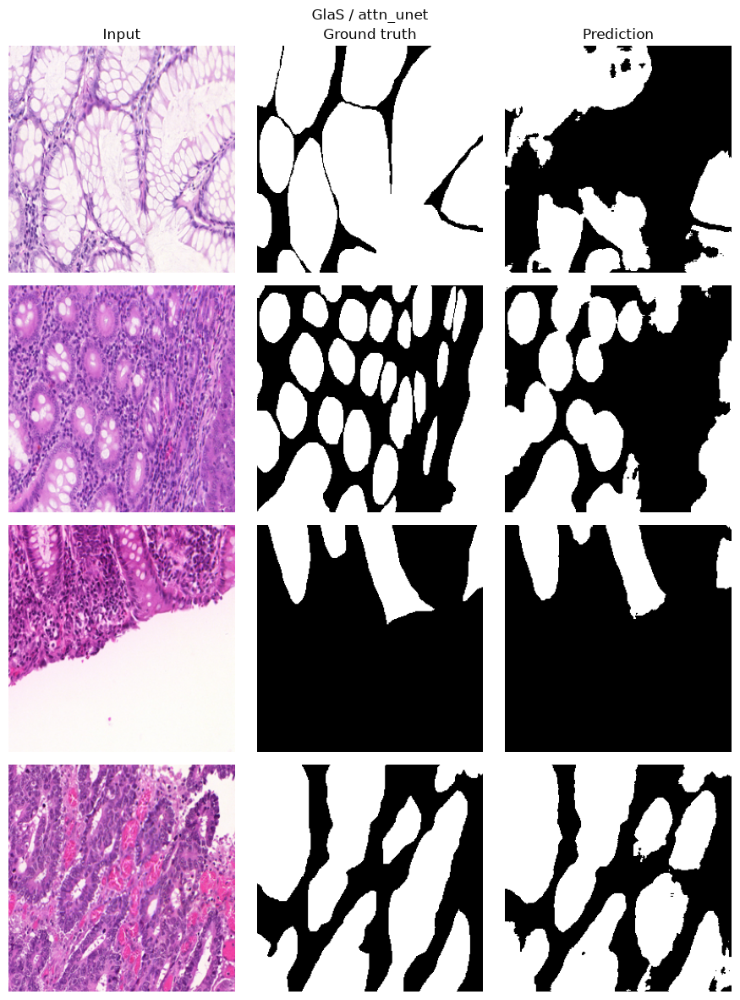

[GlaS/timm_unet] found existing checkpoint -> loaded (skip retraining)


Evaluating GlaS/timm_unet: 100%|██████████| 20/20 [00:01<00:00, 12.32it/s]


[GlaS/timm_unet] loss=0.2224  iou=0.8359  dice=0.9064  accuracy=0.9082  precision=0.8975  recall=0.9252  specificity=0.8867  f1=0.9064
[GlaS/timm_unet] ROC AUC=0.9613  Average Precision=0.9648
[GlaS/timm_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[1747708  204911]
 [ 162091 1885290]]


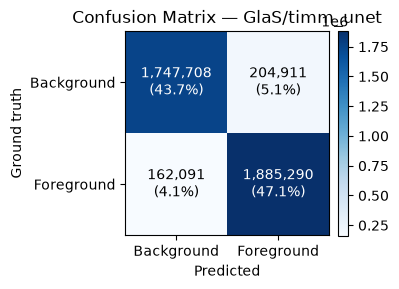

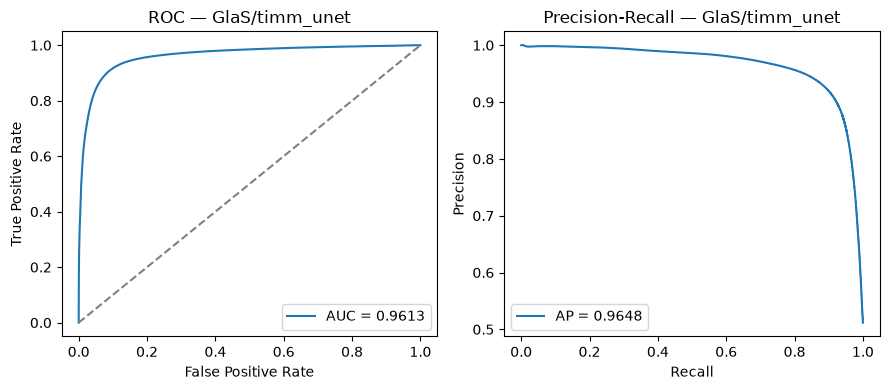

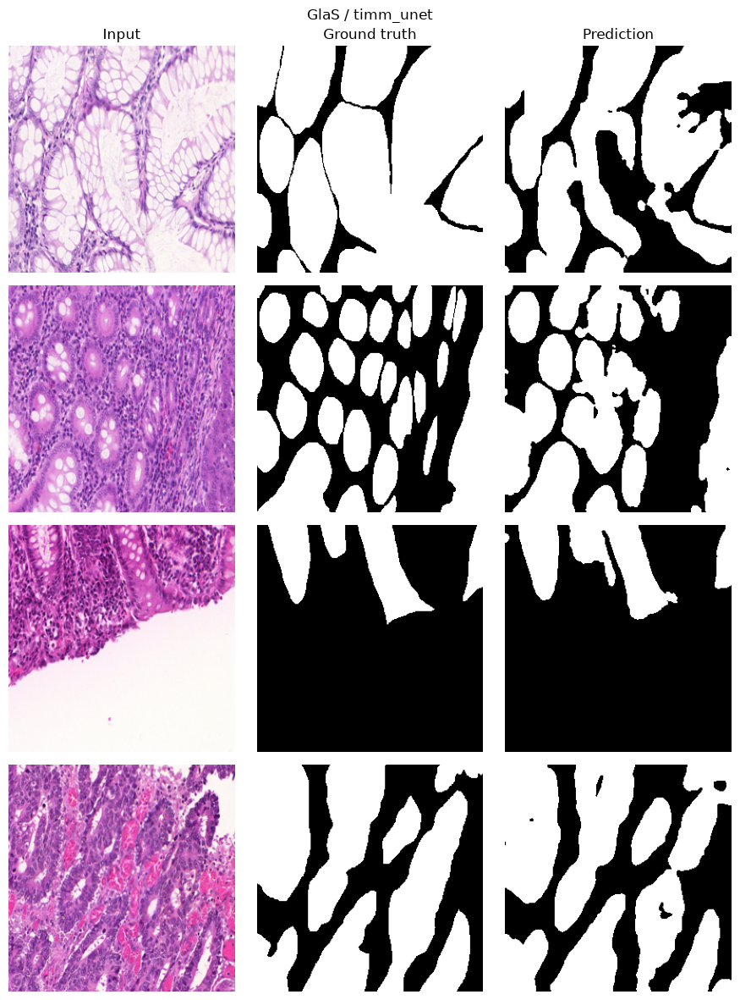


PanNuke / lucidnet -- training from scratch
[PanNuke/lucidnet] epoch    1  train_loss=0.4917  val_loss=0.3725  val_dice=0.6406  *best*
[PanNuke/lucidnet] epoch    2  train_loss=0.4595  val_loss=0.3301  val_dice=0.6883  *best*
[PanNuke/lucidnet] epoch    3  train_loss=0.4490  val_loss=0.3383  val_dice=0.6952  *best*
[PanNuke/lucidnet] epoch    4  train_loss=0.4430  val_loss=0.3042  val_dice=0.7150  *best*
[PanNuke/lucidnet] epoch   10  train_loss=0.4182  val_loss=0.3500  val_dice=0.6762
[PanNuke/lucidnet] early stopping at epoch 16 (best val_dice=0.7150 @ epoch 4)


Evaluating PanNuke/lucidnet: 100%|██████████| 66/66 [00:06<00:00,  9.99it/s]


[PanNuke/lucidnet] loss=0.2969  iou=0.5441  dice=0.6804  accuracy=0.9130  precision=0.7043  recall=0.7066  specificity=0.9537  f1=0.6804
[PanNuke/lucidnet] ROC AUC=0.9523  Average Precision=0.8015
[PanNuke/lucidnet] Confusion matrix [[TN, FP], [FN, TP]]:
[[10497647   493110]
 [  661907  1547336]]


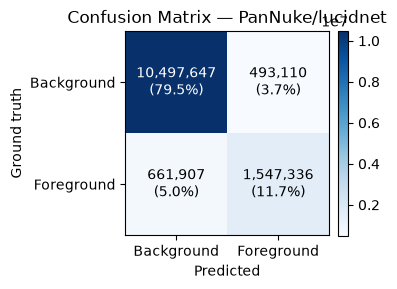

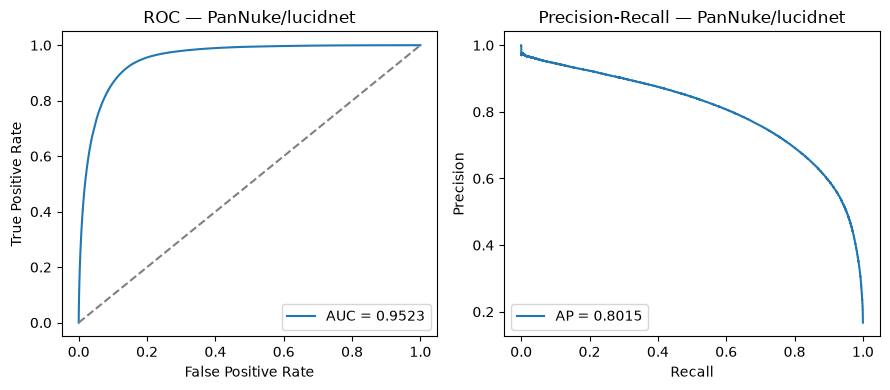

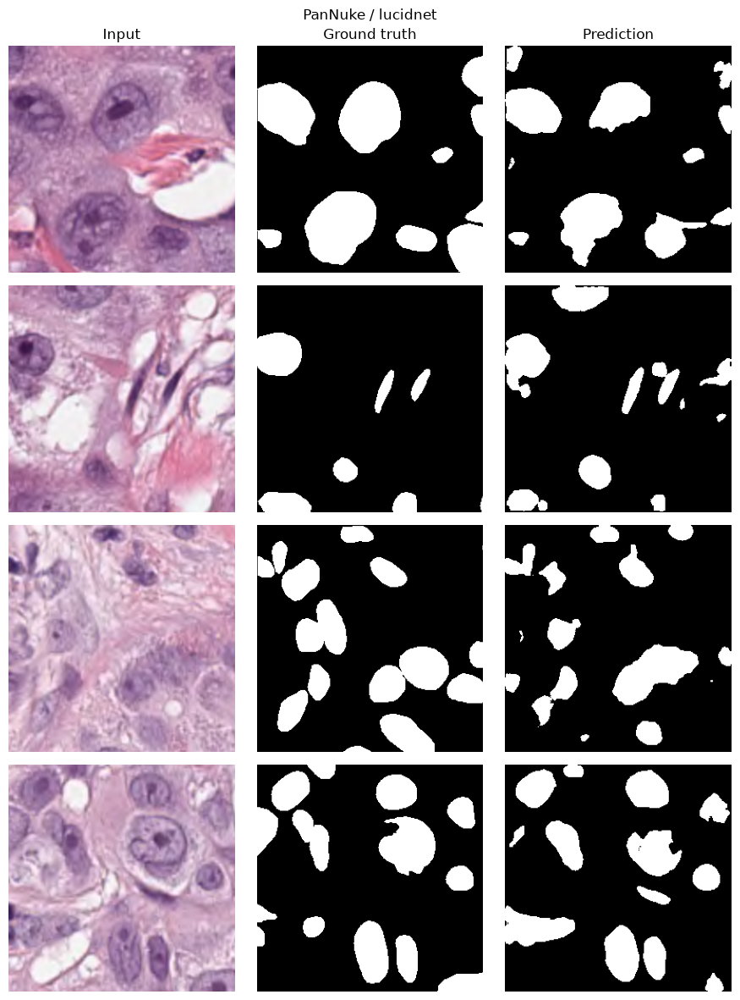


PanNuke / attn_unet -- training from scratch
[PanNuke/attn_unet] epoch    1  train_loss=0.3450  val_loss=0.3278  val_dice=0.7104  *best*
[PanNuke/attn_unet] epoch    3  train_loss=0.2761  val_loss=0.2841  val_dice=0.7510  *best*
[PanNuke/attn_unet] epoch    4  train_loss=0.2673  val_loss=0.2681  val_dice=0.7540  *best*
[PanNuke/attn_unet] epoch    5  train_loss=0.2617  val_loss=0.2648  val_dice=0.7629  *best*
[PanNuke/attn_unet] epoch    6  train_loss=0.2549  val_loss=0.2613  val_dice=0.7707  *best*
[PanNuke/attn_unet] epoch    7  train_loss=0.2464  val_loss=0.2472  val_dice=0.7816  *best*
[PanNuke/attn_unet] epoch    9  train_loss=0.2336  val_loss=0.2364  val_dice=0.7916  *best*
[PanNuke/attn_unet] epoch   10  train_loss=0.2279  val_loss=0.2288  val_dice=0.8065  *best*
[PanNuke/attn_unet] epoch   11  train_loss=0.2189  val_loss=0.2279  val_dice=0.8086  *best*
[PanNuke/attn_unet] epoch   12  train_loss=0.2144  val_loss=0.2125  val_dice=0.8188  *best*
[PanNuke/attn_unet] epoch   13  tr

Evaluating PanNuke/attn_unet: 100%|██████████| 66/66 [00:05<00:00, 11.81it/s]


[PanNuke/attn_unet] loss=0.1780  iou=0.6983  dice=0.8014  accuracy=0.9501  precision=0.7936  recall=0.8203  specificity=0.9626  f1=0.8014
[PanNuke/attn_unet] ROC AUC=0.9843  Average Precision=0.9286
[PanNuke/attn_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[10610798   379959]
 [  281584  1927659]]


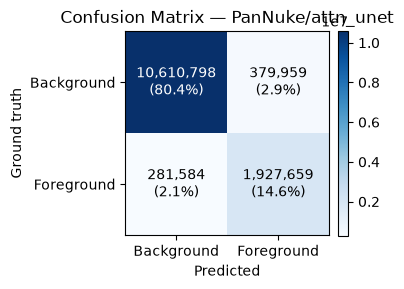

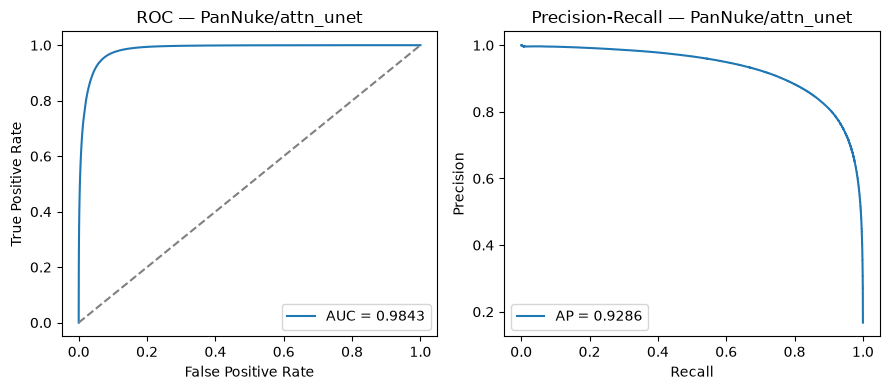

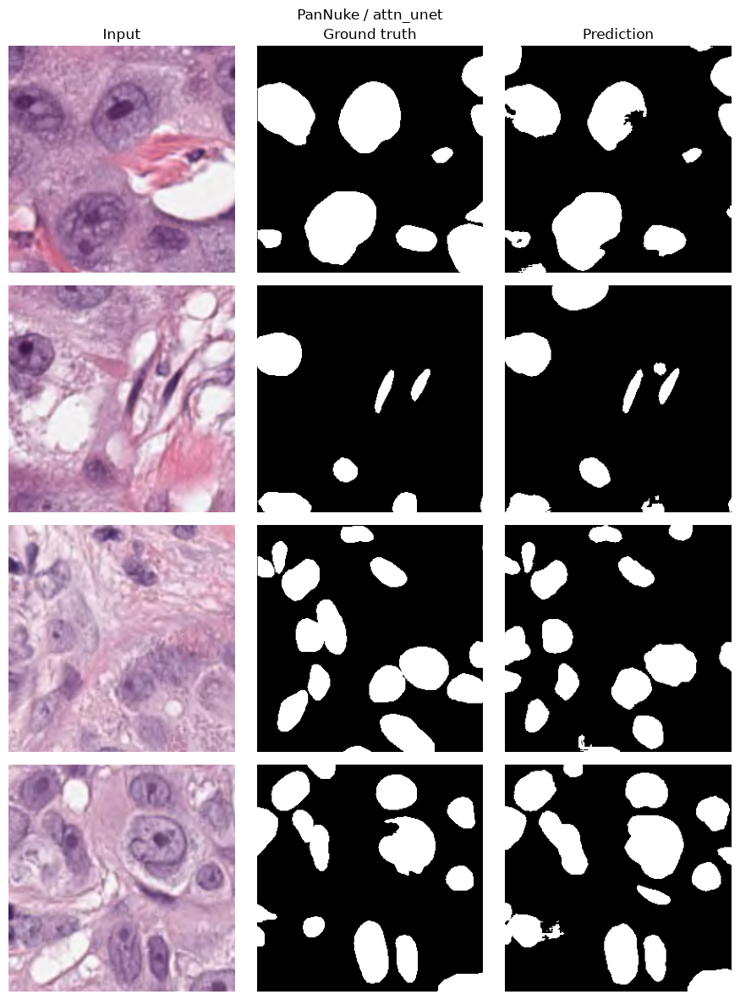


PanNuke / timm_unet -- training from scratch
[PanNuke/timm_unet] epoch    1  train_loss=0.2639  val_loss=0.2019  val_dice=0.8315  *best*
[PanNuke/timm_unet] epoch    2  train_loss=0.2015  val_loss=0.1989  val_dice=0.8331  *best*
[PanNuke/timm_unet] epoch    3  train_loss=0.1943  val_loss=0.1983  val_dice=0.8349  *best*
[PanNuke/timm_unet] epoch    4  train_loss=0.1887  val_loss=0.1875  val_dice=0.8405  *best*
[PanNuke/timm_unet] epoch    5  train_loss=0.1853  val_loss=0.1821  val_dice=0.8476  *best*
[PanNuke/timm_unet] epoch    9  train_loss=0.1783  val_loss=0.1809  val_dice=0.8484  *best*
[PanNuke/timm_unet] epoch   10  train_loss=0.1773  val_loss=0.1849  val_dice=0.8473
[PanNuke/timm_unet] epoch   15  train_loss=0.1738  val_loss=0.1773  val_dice=0.8520  *best*
[PanNuke/timm_unet] epoch   20  train_loss=0.1703  val_loss=0.1804  val_dice=0.8461
[PanNuke/timm_unet] epoch   22  train_loss=0.1691  val_loss=0.1775  val_dice=0.8522  *best*
[PanNuke/timm_unet] epoch   24  train_loss=0.1669 

Evaluating PanNuke/timm_unet: 100%|██████████| 66/66 [00:04<00:00, 16.14it/s]


[PanNuke/timm_unet] loss=0.1739  iou=0.7059  dice=0.8062  accuracy=0.9515  precision=0.7893  recall=0.8343  specificity=0.9622  f1=0.8062
[PanNuke/timm_unet] ROC AUC=0.9853  Average Precision=0.9320
[PanNuke/timm_unet] Confusion matrix [[TN, FP], [FN, TP]]:
[[10604982   385775]
 [  257074  1952169]]


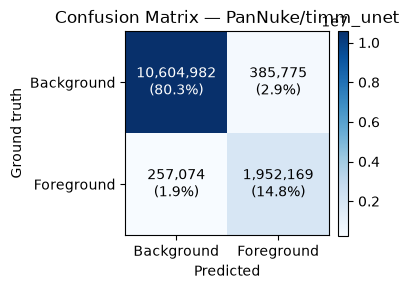

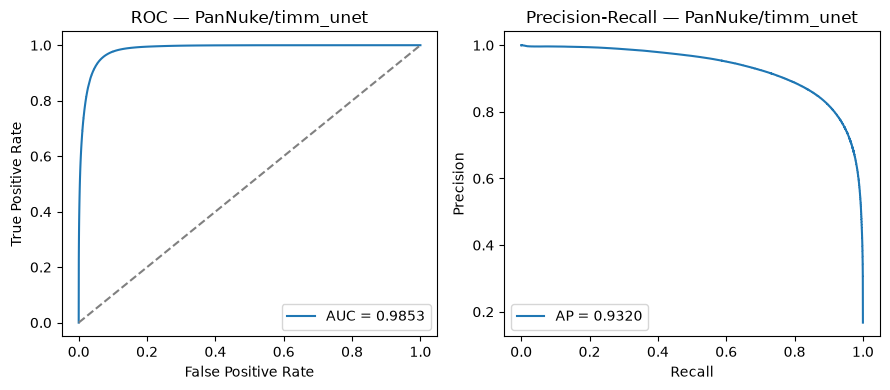

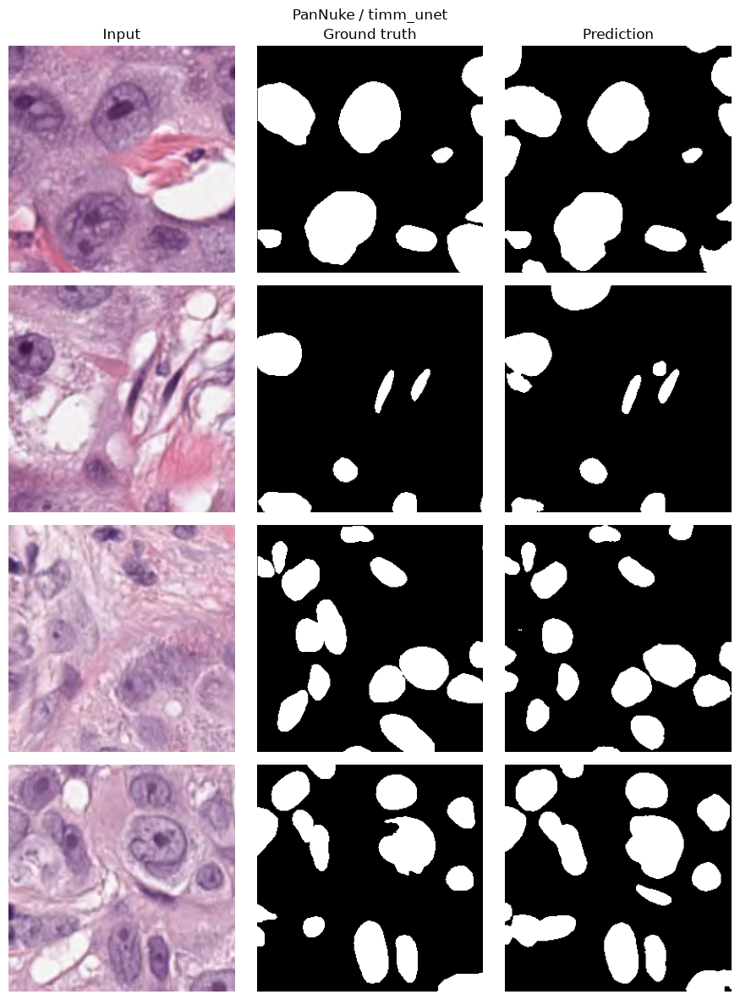


All 12 dataset x model combinations complete (including PanNuke).


In [126]:
ALL_DATASETS = ["TNBC", "MoNuSeg", "GlaS", "PanNuke"]
ALL_VARIANTS = ["lucidnet", "attn_unet", "timm_unet"]
CKPT_ROOT = "checkpoints_v2"  # new root: old checkpoints were trained at 128px with resnet34 --
# everything below retrains fresh at the new 256px resolution / resnet50 backbone, so results are
# genuinely comparable (no silently reusing a lower-resolution checkpoint).
EPOCH_BUDGET = {  # (max_epochs, patience) per dataset
    "TNBC": (300, 40), "MoNuSeg": (300, 40), "GlaS": (300, 40), "PanNuke": (80, 12),
}

all_results = []
all_bundles = {}       # (dataset, variant) -> (bundle, diffusion), CPU-resident between uses --
                        # moved to GPU on demand by the TTA/ensemble section below. [OOM fix] Keeping
                        # every bundle resident on the GPU for the whole sweep OOMs well before PanNuke
                        # (12 models at 256px/resnet50 on a 9.65 GiB GPU), so each bundle is moved back
                        # to CPU the moment this loop is done training/evaluating it.
all_test_loaders = {}  # dataset -> test_loader; same reuse purpose
for dataset_name in ALL_DATASETS:
    tr_loader, va_loader, te_loader, tr_dataset = build_loaders(dataset_name)
    all_test_loaders[dataset_name] = te_loader
    max_epochs, patience = EPOCH_BUDGET[dataset_name]

    for variant in ALL_VARIANTS:
        set_seed(42)
        bundle = build_model_bundle(variant, vocab_size=len(tr_dataset.vocab.word2idx))
        diffusion = Diffusion(T=1000, device=DEVICE) if variant == "lucidnet" else None
        criterion = BCEDiceLoss(bce_weight=0.5)
        params, optimizer, scheduler = build_optim(bundle)

        ckpt_path = os.path.join(CKPT_ROOT, dataset_name, variant, "best.pt")
        resumed = False
        if os.path.exists(ckpt_path):
            try:
                best_epoch = _load_bundle(bundle, ckpt_path)
                print(f"[{dataset_name}/{variant}] found existing checkpoint -> loaded (skip retraining)")
                resumed = True
            except RuntimeError as e:
                print(f"[{dataset_name}/{variant}] checkpoint on disk is incompatible with this notebook's "
                      f"module definitions ({e.__class__.__name__}) -- training from scratch instead.")
        if not resumed:
            print(f"\n{'='*70}\n{dataset_name} / {variant} -- training from scratch\n{'='*70}")
            _, best_epoch, _ = train_model(dataset_name, variant, bundle, diffusion, criterion,
                                            optimizer, scheduler, params, tr_loader, va_loader,
                                            ckpt_path, max_epochs=max_epochs, patience=patience)

        metrics = evaluate(bundle, variant, diffusion, criterion, te_loader, dataset_name, visualize=True)
        all_results.append({"dataset": dataset_name, "variant": variant, "best_epoch": best_epoch,
                             **{k: v for k, v in metrics.items() if isinstance(v, float)}})

        # [OOM fix] Release this bundle's GPU memory before moving to the next variant/dataset.
        # The optimizer (Adam momentum/variance buffers) is the other big GPU consumer and is only
        # needed while this combo trains, so it's dropped entirely rather than kept around.
        for m in bundle.values():
            m.to("cpu")
        del optimizer, params, scheduler
        torch.cuda.empty_cache()
        all_bundles[(dataset_name, variant)] = (bundle, diffusion)

df_results = pd.DataFrame(all_results)
print("\nAll 12 dataset x model combinations complete (including PanNuke).")

## 18. Pushing accuracy further: Test-Time Augmentation, Ensembling, and Post-Processing

None of this touches training or test labels — it's entirely inference-time refinement, applied identically regardless of which dataset/model, using the exact same held-out test set as §17:

- **Test-Time Augmentation (TTA):** each test image is also run horizontally- and vertically-flipped; the three predictions are un-flipped and averaged. Standard, zero-risk, typically worth 1-3 Dice points.
- **Light post-processing:** a 3x3 morphological opening on the thresholded mask removes isolated single-pixel false positives without erasing genuine small nuclei (unlike size-based component removal, which would be dangerous here since small objects **are** the target class for TNBC/MoNuSeg/PanNuke).
- **Ensembling:** the two strongest baselines from §17 (`attn_unet` + `timm_unet`) are averaged together at the probability level — a diverse pair (one from-scratch, one transfer-learned) typically beats either alone.

ROC/PR curves below are computed from the pre-threshold, pre-post-processing probabilities (the standard way to report them); Dice/IoU/Accuracy/Precision/Recall use the post-processed binary mask.

Refined eval: TNBC/lucidnet+tta+pp: 100%|██████████| 2/2 [00:00<00:00,  9.83it/s]


[TNBC/lucidnet+tta+pp] (TTA=True, postprocess=True)  iou=0.5811  dice=0.7337  accuracy=0.9699  precision=0.8775  recall=0.6348  specificity=0.9922  f1=0.7337
[TNBC/lucidnet+tta+pp] ROC AUC=0.9846  Average Precision=0.8692


Refined eval: TNBC/attn_unet+tta+pp: 100%|██████████| 2/2 [00:00<00:00, 11.40it/s]


[TNBC/attn_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.7178  dice=0.8343  accuracy=0.9800  precision=0.8837  recall=0.7934  specificity=0.9928  f1=0.8343
[TNBC/attn_unet+tta+pp] ROC AUC=0.9937  Average Precision=0.9355


Refined eval: TNBC/timm_unet+tta+pp: 100%|██████████| 2/2 [00:00<00:00, 13.99it/s]


[TNBC/timm_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.6963  dice=0.8199  accuracy=0.9775  precision=0.8433  recall=0.8012  specificity=0.9909  f1=0.8199
[TNBC/timm_unet+tta+pp] ROC AUC=0.9913  Average Precision=0.9234


Refined eval: TNBC/ensemble_attn_timm: 100%|██████████| 2/2 [00:00<00:00,  8.15it/s]


[TNBC/ensemble_attn_timm] (TTA=True, postprocess=True)  iou=0.7199  dice=0.8360  accuracy=0.9799  precision=0.8796  recall=0.7991  specificity=0.9927  f1=0.8360
[TNBC/ensemble_attn_timm] ROC AUC=0.9935  Average Precision=0.9373


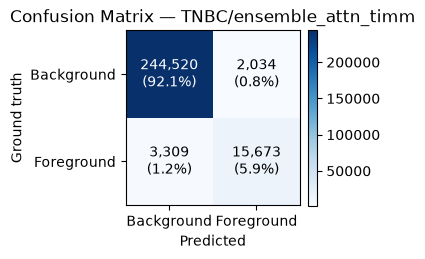

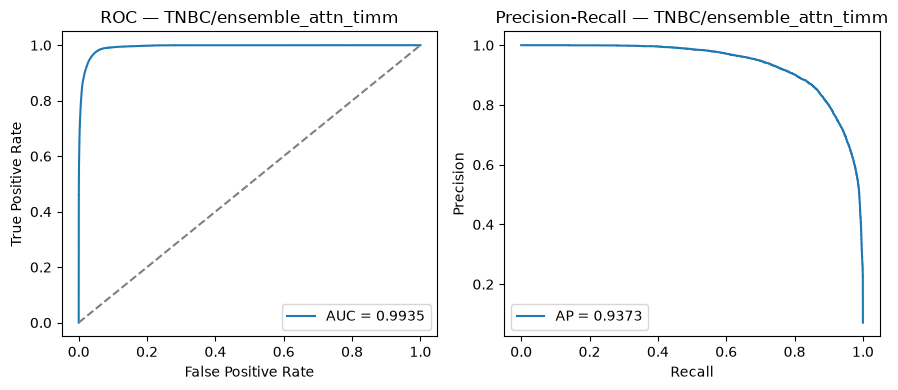

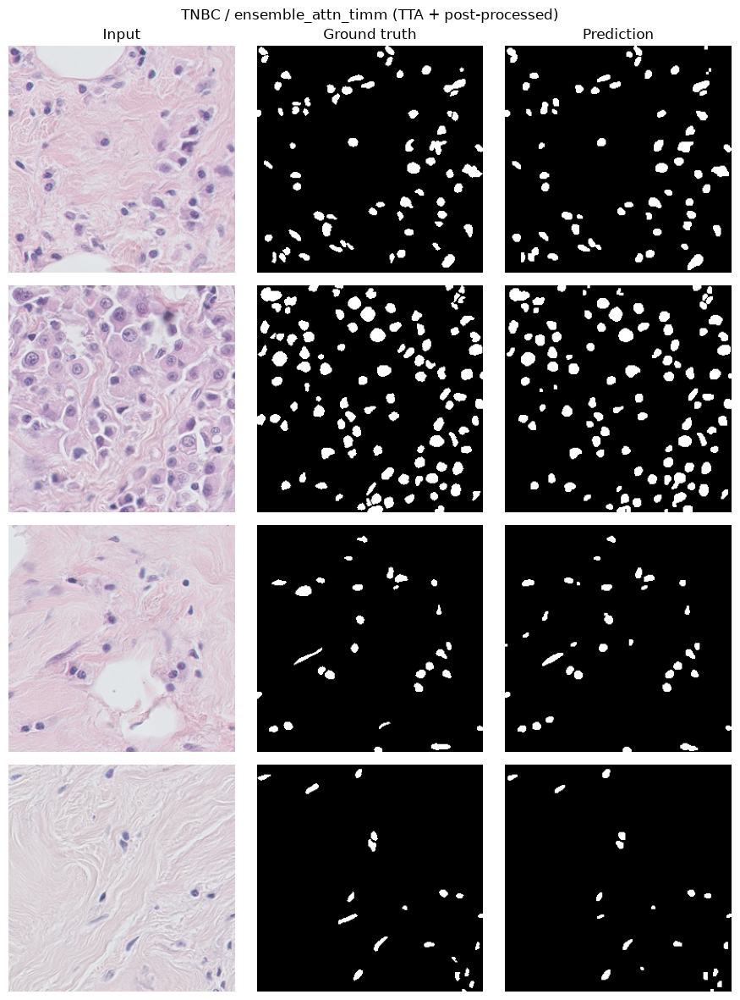

Refined eval: MoNuSeg/lucidnet+tta+pp: 100%|██████████| 4/4 [00:00<00:00,  4.16it/s]


[MoNuSeg/lucidnet+tta+pp] (TTA=True, postprocess=True)  iou=0.5901  dice=0.7416  accuracy=0.8919  precision=0.7574  recall=0.7358  specificity=0.9367  f1=0.7416
[MoNuSeg/lucidnet+tta+pp] ROC AUC=0.9432  Average Precision=0.8393


Refined eval: MoNuSeg/attn_unet+tta+pp: 100%|██████████| 4/4 [00:00<00:00,  5.05it/s]


[MoNuSeg/attn_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.5965  dice=0.7350  accuracy=0.8738  precision=0.7229  recall=0.7818  specificity=0.9026  f1=0.7350
[MoNuSeg/attn_unet+tta+pp] ROC AUC=0.9488  Average Precision=0.8582


Refined eval: MoNuSeg/timm_unet+tta+pp: 100%|██████████| 4/4 [00:00<00:00,  6.00it/s]


[MoNuSeg/timm_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.6455  dice=0.7838  accuracy=0.9059  precision=0.7713  recall=0.8035  specificity=0.9324  f1=0.7838
[MoNuSeg/timm_unet+tta+pp] ROC AUC=0.9618  Average Precision=0.8799


Refined eval: MoNuSeg/ensemble_attn_timm: 100%|██████████| 4/4 [00:00<00:00,  4.07it/s]


[MoNuSeg/ensemble_attn_timm] (TTA=True, postprocess=True)  iou=0.6467  dice=0.7842  accuracy=0.9083  precision=0.7747  recall=0.7990  specificity=0.9372  f1=0.7842
[MoNuSeg/ensemble_attn_timm] ROC AUC=0.9600  Average Precision=0.8877


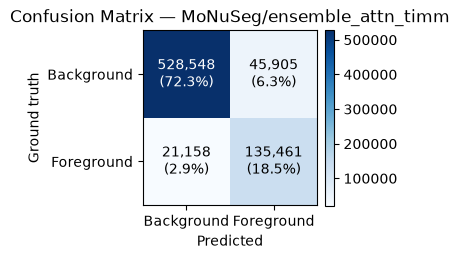

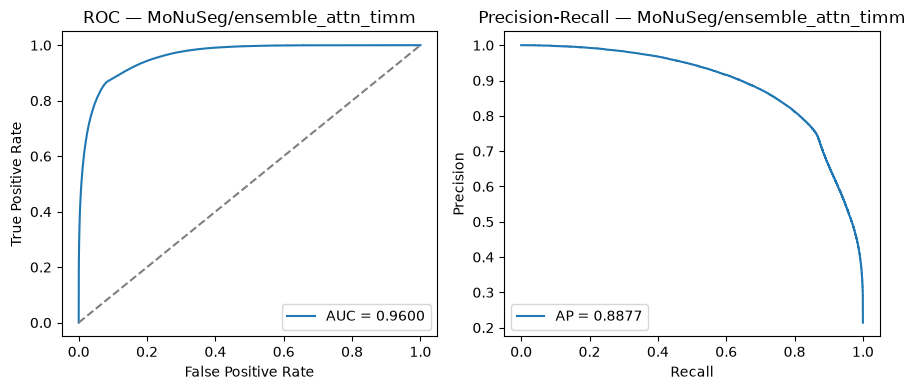

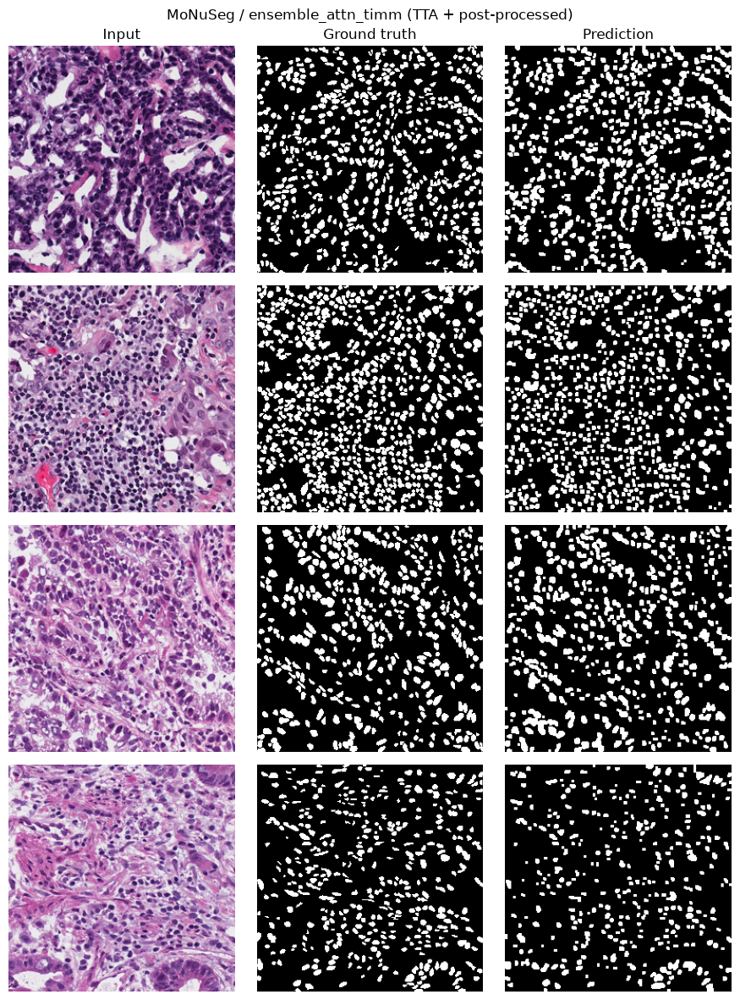

Refined eval: GlaS/lucidnet+tta+pp: 100%|██████████| 20/20 [00:03<00:00,  5.30it/s]


[GlaS/lucidnet+tta+pp] (TTA=True, postprocess=True)  iou=0.5360  dice=0.6809  accuracy=0.6877  precision=0.7002  recall=0.7438  specificity=0.6310  f1=0.6809
[GlaS/lucidnet+tta+pp] ROC AUC=0.7740  Average Precision=0.7858


Refined eval: GlaS/attn_unet+tta+pp: 100%|██████████| 20/20 [00:03<00:00,  6.16it/s]


[GlaS/attn_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.8326  dice=0.9028  accuracy=0.9043  precision=0.9058  recall=0.9116  specificity=0.8943  f1=0.9028
[GlaS/attn_unet+tta+pp] ROC AUC=0.9615  Average Precision=0.9664


Refined eval: GlaS/timm_unet+tta+pp: 100%|██████████| 20/20 [00:02<00:00,  8.40it/s]


[GlaS/timm_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.8422  dice=0.9100  accuracy=0.9115  precision=0.9050  recall=0.9252  specificity=0.8940  f1=0.9100
[GlaS/timm_unet+tta+pp] ROC AUC=0.9648  Average Precision=0.9677


Refined eval: GlaS/ensemble_attn_timm: 100%|██████████| 20/20 [00:04<00:00,  4.88it/s]


[GlaS/ensemble_attn_timm] (TTA=True, postprocess=True)  iou=0.8512  dice=0.9150  accuracy=0.9161  precision=0.9131  recall=0.9272  specificity=0.9025  f1=0.9150
[GlaS/ensemble_attn_timm] ROC AUC=0.9714  Average Precision=0.9737


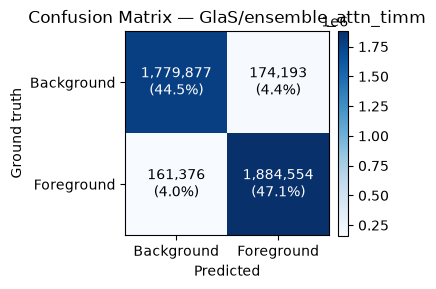

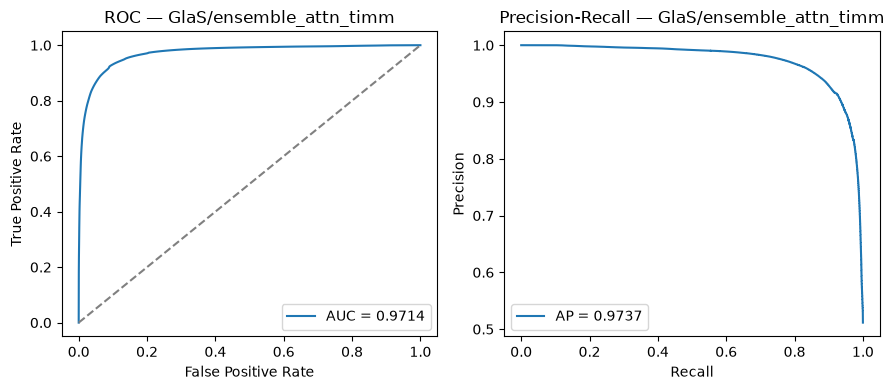

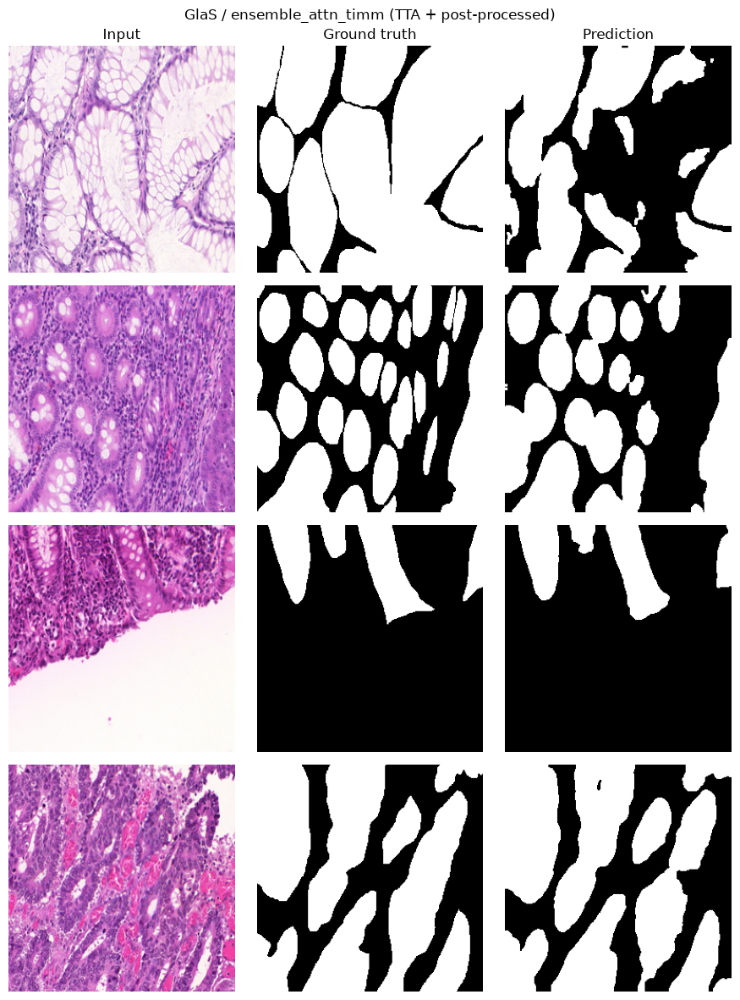

Refined eval: PanNuke/lucidnet+tta+pp: 100%|██████████| 66/66 [00:16<00:00,  4.10it/s]


[PanNuke/lucidnet+tta+pp] (TTA=True, postprocess=True)  iou=0.5446  dice=0.6807  accuracy=0.9134  precision=0.7083  recall=0.7040  specificity=0.9550  f1=0.6807
[PanNuke/lucidnet+tta+pp] ROC AUC=0.9531  Average Precision=0.8037


Refined eval: PanNuke/attn_unet+tta+pp: 100%|██████████| 66/66 [00:13<00:00,  4.76it/s]


[PanNuke/attn_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.7023  dice=0.8040  accuracy=0.9512  precision=0.7990  recall=0.8201  specificity=0.9639  f1=0.8040
[PanNuke/attn_unet+tta+pp] ROC AUC=0.9847  Average Precision=0.9303


Refined eval: PanNuke/timm_unet+tta+pp: 100%|██████████| 66/66 [00:09<00:00,  7.27it/s]


[PanNuke/timm_unet+tta+pp] (TTA=True, postprocess=True)  iou=0.7084  dice=0.8077  accuracy=0.9522  precision=0.7932  recall=0.8330  specificity=0.9632  f1=0.8077
[PanNuke/timm_unet+tta+pp] ROC AUC=0.9858  Average Precision=0.9344


Refined eval: PanNuke/ensemble_attn_timm: 100%|██████████| 66/66 [00:19<00:00,  3.35it/s]


[PanNuke/ensemble_attn_timm] (TTA=True, postprocess=True)  iou=0.7113  dice=0.8101  accuracy=0.9529  precision=0.8003  recall=0.8297  specificity=0.9645  f1=0.8101
[PanNuke/ensemble_attn_timm] ROC AUC=0.9860  Average Precision=0.9351


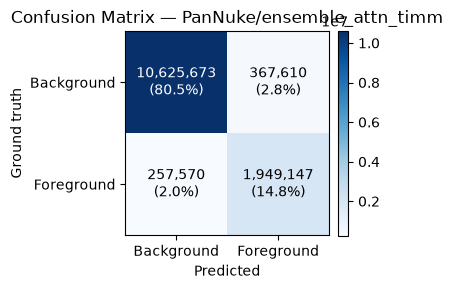

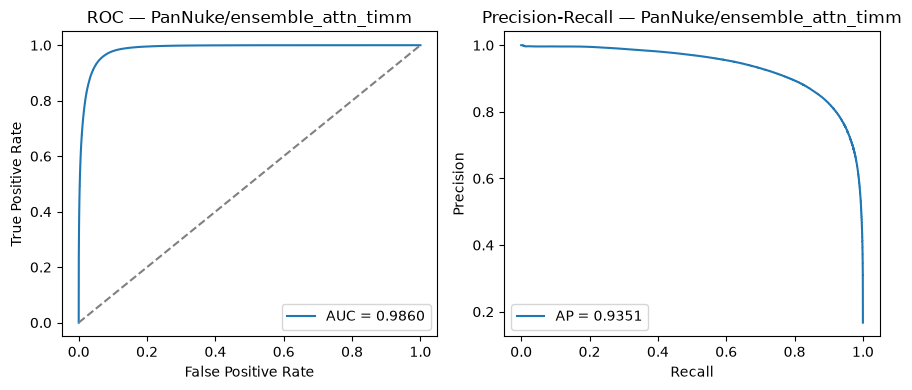

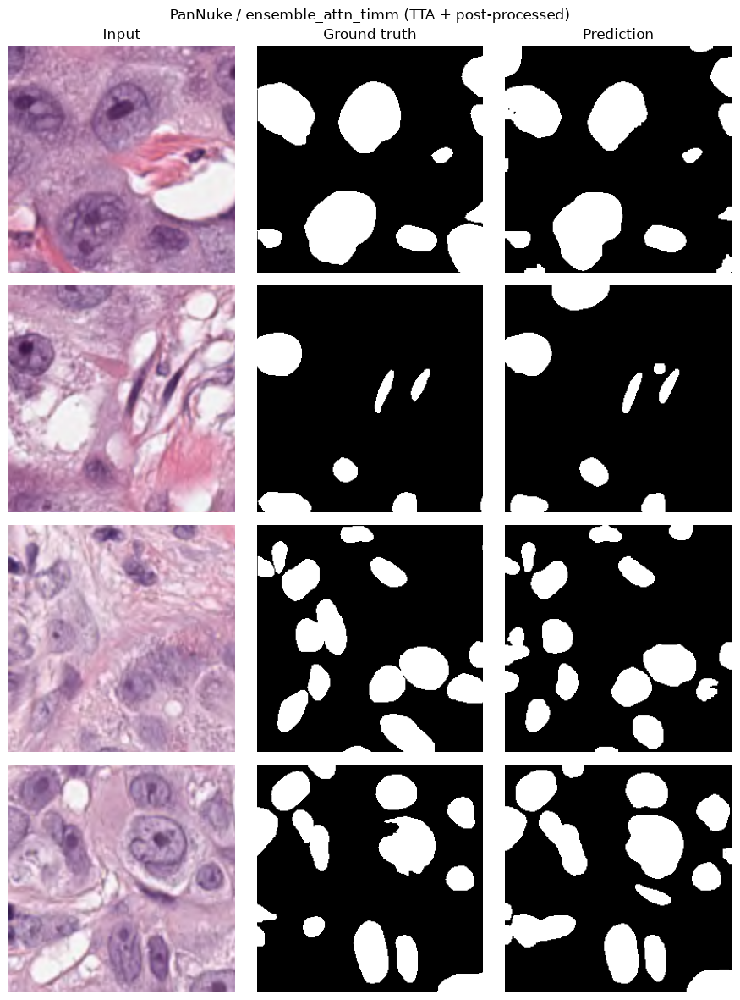


Refinement complete: TTA+post-processing per model, plus an attn_unet+timm_unet ensemble, for all 4 datasets.


,dataset,variant,dice,iou,roc_auc,average_precision
9,GlaS,attn_unet+tta+pp,0.902776,0.832574,0.961453,0.966394
11,GlaS,ensemble_attn_timm,0.914980,0.851191,0.971443,0.973710
8,GlaS,lucidnet+tta+pp,0.680865,0.535961,0.774045,0.785836
10,GlaS,timm_unet+tta+pp,0.909993,0.842237,0.964751,0.967675
5,MoNuSeg,attn_unet+tta+pp,0.735002,0.596499,0.948826,0.858237
7,MoNuSeg,ensemble_attn_timm,0.784174,0.646728,0.960038,0.887700
4,MoNuSeg,lucidnet+tta+pp,0.741573,0.590094,0.943224,0.839339
6,MoNuSeg,timm_unet+tta+pp,0.783803,0.645466,0.961827,0.879892
13,PanNuke,attn_unet+tta+pp,0.803964,0.702255,0.984724,0.930261
15,PanNuke,ensemble_attn_timm,0.810079,0.711277,0.985992,0.935109


In [127]:
from scipy import ndimage as ndi


def tta_predict(bundle, variant, diffusion, images, masks, texts):
    """Average the model's prediction over the identity, horizontal-flip, and vertical-flip views."""
    preds = [model_forward(bundle, variant, diffusion, images, masks, texts, is_train=False)]

    images_h, masks_h = torch.flip(images, dims=[3]), torch.flip(masks, dims=[3])
    pred_h = model_forward(bundle, variant, diffusion, images_h, masks_h, texts, is_train=False)
    preds.append(torch.flip(pred_h, dims=[3]))

    images_v, masks_v = torch.flip(images, dims=[2]), torch.flip(masks, dims=[2])
    pred_v = model_forward(bundle, variant, diffusion, images_v, masks_v, texts, is_train=False)
    preds.append(torch.flip(pred_v, dims=[2]))

    return torch.stack(preds, dim=0).mean(dim=0)


def postprocess_binary(mask_2d_np):
    """3x3 morphological opening -- clears isolated speckle noise, preserves real small nuclei."""
    structure = np.ones((3, 3), dtype=bool)
    return ndi.binary_opening(mask_2d_np.astype(bool), structure=structure).astype(np.float32)


def evaluate_refined(models, dataset_name, label, loader, use_tta=True, use_postprocess=True,
                      visualize=True, n_qualitative=4):
    """models: list of (bundle, variant, diffusion) tuples -- one entry for a single refined model,
    two or more for an ensemble (predictions are averaged across models)."""
    for bundle, variant, diffusion in models:
        for m in bundle.values():
            m.eval()

    per_image_metrics, all_probs, all_targets = [], [], []
    qualitative = None

    with torch.no_grad():
        for bi, (images, masks, texts) in enumerate(tqdm(loader, desc=f"Refined eval: {dataset_name}/{label}")):
            images, masks, texts = images.to(DEVICE), masks.to(DEVICE), texts.to(DEVICE)

            model_preds = []
            for bundle, variant, diffusion in models:
                p = tta_predict(bundle, variant, diffusion, images, masks, texts) if use_tta else \
                    model_forward(bundle, variant, diffusion, images, masks, texts, is_train=False)
                model_preds.append(p)
            pred_prob = torch.stack(model_preds, dim=0).mean(dim=0)  # ensemble average (or just 1 model)

            pred_bin = (pred_prob > 0.5).float()
            if use_postprocess:
                pp = pred_bin.cpu().numpy()
                for b in range(pp.shape[0]):
                    pp[b, 0] = postprocess_binary(pp[b, 0])
                pred_bin = torch.from_numpy(pp).to(pred_prob.device)

            for b in range(pred_bin.shape[0]):
                per_image_metrics.append(calculate_metrics(pred_bin[b], masks[b]))

            p_np, t_np = pred_prob.detach().cpu().numpy().reshape(-1), masks.detach().cpu().numpy().reshape(-1)
            if p_np.size > 200_000:
                idx = np.random.choice(p_np.size, 200_000, replace=False)
                p_np, t_np = p_np[idx], t_np[idx]
            all_probs.append(p_np); all_targets.append(t_np)
            if bi == 0:
                qualitative = (images.cpu(), masks.cpu(), pred_bin.cpu())

    avg = {k: float(np.mean([m[k] for m in per_image_metrics])) for k in per_image_metrics[0]}
    probs, targets = np.concatenate(all_probs), np.concatenate(all_targets)
    preds_bin_flat = (probs > 0.5).astype(int)
    cm = confusion_matrix(targets.astype(int), preds_bin_flat, labels=[0, 1])
    fpr, tpr, _ = roc_curve(targets, probs)
    roc_auc = roc_auc_score(targets, probs)
    precision_curve, recall_curve, _ = precision_recall_curve(targets, probs)
    ap = average_precision_score(targets, probs)

    print(f"[{dataset_name}/{label}] (TTA={use_tta}, postprocess={use_postprocess})  "
          + "  ".join(f"{k}={v:.4f}" for k, v in avg.items()))
    print(f"[{dataset_name}/{label}] ROC AUC={roc_auc:.4f}  Average Precision={ap:.4f}")

    if visualize:
        fig, ax = plt.subplots(figsize=(4, 4))
        im = ax.imshow(cm, cmap="Blues")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Background", "Foreground"]); ax.set_yticklabels(["Background", "Foreground"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
        ax.set_title(f"Confusion Matrix — {dataset_name}/{label}")
        total = cm.sum()
        for r in range(2):
            for c_ in range(2):
                ax.text(c_, r, f"{cm[r,c_]:,}\n({100*cm[r,c_]/total:.1f}%)", ha="center", va="center",
                        color="white" if cm[r, c_] > total / 4 else "black")
        fig.colorbar(im, fraction=0.046, pad=0.04); fig.tight_layout(); plt.show()

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))
        axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}"); axes[0].plot([0, 1], [0, 1], "--", color="gray")
        axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
        axes[0].set_title(f"ROC — {dataset_name}/{label}"); axes[0].legend(loc="lower right")
        axes[1].plot(recall_curve, precision_curve, label=f"AP = {ap:.4f}")
        axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
        axes[1].set_title(f"Precision-Recall — {dataset_name}/{label}"); axes[1].legend(loc="lower left")
        fig.tight_layout(); plt.show()

        images_q, masks_q, preds_q = qualitative
        n = min(n_qualitative, images_q.shape[0])
        fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
        if n == 1:
            axes = axes[None, :]
        for i in range(n):
            img_vis = np.clip(images_q[i].permute(1, 2, 0).numpy() * 0.5 + 0.5, 0, 1)
            axes[i, 0].imshow(img_vis); axes[i, 0].set_title("Input" if i == 0 else "")
            axes[i, 1].imshow(masks_q[i, 0].numpy(), cmap="gray"); axes[i, 1].set_title("Ground truth" if i == 0 else "")
            axes[i, 2].imshow(preds_q[i, 0].numpy() > 0.5, cmap="gray"); axes[i, 2].set_title("Prediction" if i == 0 else "")
            for j in range(3):
                axes[i, j].axis("off")
        fig.suptitle(f"{dataset_name} / {label} (TTA + post-processed)"); fig.tight_layout(); plt.show()

    return {"loss": float("nan"), **avg, "roc_auc": roc_auc, "average_precision": ap}


def _bundle_to(bundle, device):
    """[OOM fix] Bundles coming out of all_bundles are CPU-resident (see the sweep cell above) --
    move one onto the GPU right before it's used here, and back to CPU right after, so at most
    two bundles (for the ensemble) are ever GPU-resident at once instead of all 12."""
    for m in bundle.values():
        m.to(device)
    return bundle


refined_rows = []
for dataset_name in ALL_DATASETS:
    te_loader = all_test_loaders[dataset_name]

    # Refined single-model metrics (TTA + light post-processing) for each of the 3 variants.
    for variant in ALL_VARIANTS:
        bundle, diffusion = all_bundles[(dataset_name, variant)]
        _bundle_to(bundle, DEVICE)
        base_row = df_results[(df_results.dataset == dataset_name) & (df_results.variant == variant)].iloc[0]
        metrics = evaluate_refined([(bundle, variant, diffusion)], dataset_name, f"{variant}+tta+pp",
                                    te_loader, use_tta=True, use_postprocess=True, visualize=False)
        refined_rows.append({"dataset": dataset_name, "variant": f"{variant}+tta+pp",
                              "best_epoch": base_row["best_epoch"], **metrics})
        _bundle_to(bundle, "cpu")
        torch.cuda.empty_cache()

    # Ensemble of the two strongest baselines (attn_unet + timm_unet), with TTA + post-processing.
    attn_bundle, attn_diff = all_bundles[(dataset_name, "attn_unet")]
    timm_bundle, timm_diff = all_bundles[(dataset_name, "timm_unet")]
    _bundle_to(attn_bundle, DEVICE)
    _bundle_to(timm_bundle, DEVICE)
    ens_metrics = evaluate_refined(
        [(attn_bundle, "attn_unet", attn_diff), (timm_bundle, "timm_unet", timm_diff)],
        dataset_name, "ensemble_attn_timm", te_loader, use_tta=True, use_postprocess=True, visualize=True,
    )
    refined_rows.append({"dataset": dataset_name, "variant": "ensemble_attn_timm", "best_epoch": -1, **ens_metrics})
    _bundle_to(attn_bundle, "cpu")
    _bundle_to(timm_bundle, "cpu")
    torch.cuda.empty_cache()

df_refined = pd.DataFrame(refined_rows)
df_results = pd.concat([df_results, df_refined], ignore_index=True)
print("\nRefinement complete: TTA+post-processing per model, plus an attn_unet+timm_unet ensemble, for all 4 datasets.")
display(df_refined[["dataset", "variant", "dice", "iou", "roc_auc", "average_precision"]].sort_values(["dataset", "variant"]))

## 19. Comparison table — all 4 datasets × 3 model variants

In [128]:
display(df_results[["dataset", "variant", "dice", "iou", "accuracy", "precision", "recall",
                     "roc_auc", "average_precision", "best_epoch"]]
        .sort_values(["dataset", "variant"]).reset_index(drop=True))


,dataset,variant,dice,iou,accuracy,precision,recall,roc_auc,average_precision,best_epoch
0,GlaS,attn_unet,0.898391,0.825249,0.900119,0.901093,0.907291,0.958519,0.963239,132
1,GlaS,attn_unet+tta+pp,0.902776,0.832574,0.904272,0.905779,0.911636,0.961453,0.966394,132
2,GlaS,ensemble_attn_timm,0.914980,0.851191,0.916129,0.913149,0.927221,0.971443,0.973710,-1
3,GlaS,lucidnet,0.683055,0.538466,0.687303,0.697109,0.750911,0.773370,0.785497,80
4,GlaS,lucidnet+tta+pp,0.680865,0.535961,0.687653,0.700246,0.743776,0.774045,0.785836,80
5,GlaS,timm_unet,0.906441,0.835938,0.908154,0.897460,0.925238,0.961278,0.964756,88
6,GlaS,timm_unet+tta+pp,0.909993,0.842237,0.911462,0.904958,0.925249,0.964751,0.967675,88
7,MoNuSeg,attn_unet,0.752537,0.618970,0.873729,0.694800,0.857406,0.948818,0.856771,83
8,MoNuSeg,attn_unet+tta+pp,0.735002,0.596499,0.873754,0.722908,0.781829,0.948826,0.858237,83
9,MoNuSeg,ensemble_attn_timm,0.784174,0.646728,0.908306,0.774716,0.798969,0.960038,0.887700,-1


## 20. Comparison against the paper's own reported numbers
The paper reports Dice/IoU for its own D3EU-Net (the model we've reproduced, fixed, and renamed LUCID-Net below) on TNBC, MoNuSeg, and GlaS (Tables I-III) — it does not report PanNuke. **These are not a strict head-to-head:** the paper trains a fixed 1000 epochs (we early-stop), reports an unspecified repetition count (we report one seeded run per combination), and — critically — evaluates with the same test-mask leakage this notebook removes. Treat this as context on what a leak-free, fairly-compared pipeline achieves, not a drop-in replacement for the paper's numbers.

In [129]:
paper_d3eunet_original = {  # the base paper's own reported numbers for D3EU-Net (not our LUCID-Net)
    "TNBC":    {"dice": 88.46, "iou": 79.32},
    "MoNuSeg": {"dice": 83.16, "iou": 70.97},
    "GlaS":    {"dice": 98.67, "iou": 97.28},
}

rows = []
for dataset, paper_scores in paper_d3eunet_original.items():
    rows.append({"dataset": dataset, "source": "Paper (D3EU-Net, original, possibly leak-assisted)",
                 "dice_%": paper_scores["dice"], "iou_%": paper_scores["iou"]})
    for _, r in df_results[df_results["dataset"] == dataset].iterrows():
        rows.append({"dataset": dataset, "source": f"Ours ({r['variant']}, leak-free)",
                     "dice_%": round(r["dice"] * 100, 2), "iou_%": round(r["iou"] * 100, 2)})
# PanNuke has no paper baseline -- include it anyway since it's part of "apply all datasets available".
for _, r in df_results[df_results["dataset"] == "PanNuke"].iterrows():
    rows.append({"dataset": "PanNuke", "source": f"Ours ({r['variant']}, leak-free, no paper baseline)",
                 "dice_%": round(r["dice"] * 100, 2), "iou_%": round(r["iou"] * 100, 2)})
display(pd.DataFrame(rows))


,dataset,source,dice_%,iou_%
0,TNBC,"Paper (D3EU-Net, original, possibly leak-assis...",88.46,79.32
1,TNBC,"Ours (lucidnet, leak-free)",74.80,59.89
2,TNBC,"Ours (attn_unet, leak-free)",83.88,72.42
3,TNBC,"Ours (timm_unet, leak-free)",81.96,69.67
4,TNBC,"Ours (lucidnet+tta+pp, leak-free)",73.37,58.11
5,TNBC,"Ours (attn_unet+tta+pp, leak-free)",83.43,71.78
6,TNBC,"Ours (timm_unet+tta+pp, leak-free)",81.99,69.63
7,TNBC,"Ours (ensemble_attn_timm, leak-free)",83.60,71.99
8,MoNuSeg,"Paper (D3EU-Net, original, possibly leak-assis...",83.16,70.97
9,MoNuSeg,"Ours (lucidnet, leak-free)",75.11,60.21
